# Visual Mapping: Титаник өгөгдөл дээрх бодит хэрэгжүүлэлт

**Visual Mapping** гэдэг нь өгөгдлийн талбар бүрийг харааны хувьсагч (байрлал, урт, өнгө, хэмжээ, хэлбэр…) руу *зориуд* холбох үйл явц юм. Үүнд хоёр гол асуулт бий:

| # | Асуулт | Утга | Энэ notebook-д |
|---|---|---|---|
| 1 | **Юуг холбох вэ?** (*What to map*) | Зорилгоосоо эхэлж, тохирох өгөгдлийн талбаруудыг сонгох, төрлийг нь тодорхойлох | 3 зорилго: амьд үлдэх · нийгмийн давхарга · гэр бүлийн нөлөө |
| 2 | **Хэрхэн холбох вэ?** (*How to map*) | Талбар бүрийг хүний хараа хамгийн хурдан, нарийн уншдаг сувагт оноох | Preattentive processing: өнгө, хэмжээ, байрлал |

Бүтэц:
1. Өгөгдөл бэлтгэх
2. **Юуг холбох вэ?** — 3 зорилго, талбарын сонголт, mapping хүснэгт
3. **Хэрхэн холбох вэ?** — preattentive туршилт, сувгийн нарийвчлалын эрэмбэ, өнгөний дүрэм
4. Зорилго бүрийн хэрэгжүүлэлт (гол олдвортой график)
5. **Практик харьцуулалт** — буруу vs зөв, энгийн хүснэгт vs visual mapping
6. Гол олдворууд — нэгтгэсэн самбар

## 0. Тохиргоо: сан, өнгөний систем, графикийн загвар

Өнгийг **үүргээр** нь сонгосон (санамсаргүй биш):

| Үүрэг | Хэзээ | Энд хэрэглэсэн |
|---|---|---|
| **Ангиллын (categorical)** | Хэн/юу гэдгийг ялгах (хүйс) | Цэнхэр `#2a78d6` = Эмэгтэй, Улбар шар `#eb6834` = Эрэгтэй — өнгөний харалган (CVD) хүнд ч ялгагдана (ΔE 24.7) |
| **Дараалсан (ordinal/sequential)** | Эрэмбэтэй утга (зэрэглэл, хэмжээ) | Нэг өнгө, цайвараас бараан руу: 3-р → 2-р → 1-р зэрэг |
| **Хоёр туйлт (diverging)** | Дунджаас дээш/доош | Улаан ← саарал (дундаж 38.4%) → цэнхэр |
| **Онцлох (emphasis)** | Нэг гол олдворыг гаргах | Онцлох өнгө + бусдыг саарал |

Өнгө нь **хэзээ ч ганцаараа** утга зөөхгүй — шууд шошго, тайлбар (legend) үргэлж хамт байна.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
from matplotlib.patches import Patch
import warnings; warnings.filterwarnings('ignore')

# ── Өнгөний систем (CVD-д шалгагдсан палитр) ─────────────────
C = dict(
    blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', red='#e34948',
    gray='#c3c2b7', light_gray='#e1e0d9', muted='#898781',
    ink='#0b0b0b', ink2='#52514e', surface='#fcfcfb', mid='#f0efec',
)
SEX_COLOR   = {'Эмэгтэй': C['blue'], 'Эрэгтэй': C['orange']}          # ангиллын
CLASS_COLOR = {1: '#104281', 2: '#2a78d6', 3: '#86b6ef'}              # дараалсан (1-р зэрэг = хамгийн бараан)
DIVERGING   = LinearSegmentedColormap.from_list('div', [C['red'], C['mid'], C['blue']])
SEQUENTIAL  = LinearSegmentedColormap.from_list('seq', ['#cde2fb', '#2a78d6', '#0d366b'])

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'],
    'savefig.facecolor': C['surface'], 'figure.dpi': 110,
    'axes.edgecolor': C['gray'], 'axes.labelcolor': C['ink2'],
    'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.titlecolor': C['ink'],
    'axes.titlelocation': 'left', 'axes.titlepad': 24,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': C['light_gray'], 'grid.linewidth': 0.6,
    'axes.axisbelow': True,
    'xtick.color': C['muted'], 'ytick.color': C['muted'],
    'xtick.labelcolor': C['ink2'], 'ytick.labelcolor': C['ink2'],
    'legend.frameon': False, 'lines.linewidth': 2,
})
PCT = mtick.PercentFormatter(1.0, decimals=0)

def subtitle(ax, text):
    # Гарчгийн доор саарал тайлбар мөр
    ax.text(0, 1.015, text, transform=ax.transAxes, fontsize=9.5, color=C['ink2'], va='bottom')

def text_on(hex_color):
    # Будсан нүдэн дээрх бичгийн өнгө: цайвар дээр бараан, бараан дээр цагаан
    r, g, b = to_rgb(hex_color)
    return C['ink'] if (0.299*r + 0.587*g + 0.114*b) > 0.6 else 'white'
print('Бэлэн')

Бэлэн


## 1. Өгөгдөл бэлтгэх

In [2]:
DATA_PATH = 'titanic.csv'          # шаардлагатай бол замыг өөрчилнө
df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())
display(df.isna().sum().to_frame('Дутуу утга').T)

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Дутуу утга,0,0,0,0,0,177,0,0,0,0,687,2


**Шинэ (derived) талбарууд** — mapping хийхийн өмнө өгөгдлийг асуултад тохирох хэлбэрт оруулна:
- `Хүйс` — Монгол шошго
- `Зэрэг` — 1/2/3-р зэргийн бүхээг (**эрэмбэтэй**)
- `Насны_бүлэг` — 0–12, 13–18, 19–35, 36–60, 60+ (**эрэмбэтэй**); 177 зорчигчийн нас тодорхойгүй тул насны шинжилгээнд ороогүй
- `Гэр_бүл` = SibSp + Parch + 1 (өөрийгөө оруулаад); `Гэр_бүлийн_төрөл` — Ганцаараа / Жижиг (2–4) / Том (5+)

In [3]:
df['Хүйс'] = df['Sex'].map({'female': 'Эмэгтэй', 'male': 'Эрэгтэй'})
df['Зэрэг'] = df['Pclass']
df['Зэрэг_нэр'] = df['Pclass'].map({1: '1-р зэрэг', 2: '2-р зэрэг', 3: '3-р зэрэг'})
AGE_ORDER = ['0–12', '13–18', '19–35', '36–60', '60+']
df['Насны_бүлэг'] = pd.cut(df['Age'], [0, 12, 18, 35, 60, 100], labels=AGE_ORDER)
df['Гэр_бүл'] = df['SibSp'] + df['Parch'] + 1
FAM_ORDER = ['Ганцаараа', 'Жижиг (2–4)', 'Том (5+)']
df['Гэр_бүлийн_төрөл'] = pd.cut(df['Гэр_бүл'], [0, 1, 4, 20], labels=FAM_ORDER)

OVERALL = df['Survived'].mean()
print(f'Нийт зорчигч: {len(df)} · Амьд үлдсэн: {df.Survived.sum()} · Нийт амьд үлдэлт: {OVERALL:.1%}')

Нийт зорчигч: 891 · Амьд үлдсэн: 342 · Нийт амьд үлдэлт: 38.4%


---
# 2. Асуулт 1 — «Юуг холбох вэ?» (*What to map*)

Visual mapping **графикийн төрлөөс биш, зорилгоос** эхэлнэ. Нэг өгөгдлөөс өөр өөр асуулт тавихад өөр талбарууд чухал болно. Бид 3 зорилго тодорхойлов:

| Зорилго | Судалгааны асуулт | Гол талбар (зорилт) | Тайлбарлагч талбарууд |
|---|---|---|---|
| **З1. Амьд үлдэх** | Хэн амьд үлдэх магадлал өндөр байсан бэ? «Эмэгтэй, хүүхэд түрүүлж» дүрэм биелсэн үү? | `Survived` | `Sex`, `Age` → `Насны_бүлэг` |
| **З2. Нийгмийн давхарга** | Бүхээгийн зэрэг, төлбөр амьд үлдэлтэд нөлөөлсөн үү? | `Survived` | `Pclass`, `Fare`, `Sex` (хяналтын) |
| **З3. Гэр бүлийн нөлөө** | Ганцаараа эсвэл гэр бүлтэйгээ явах нь давуу тал байсан уу? | `Survived` | `SibSp`, `Parch` → `Гэр_бүл` |

**Сонгоогүй талбарууд ба шалтгаан:** `Name`, `Ticket`, `PassengerId` — асуултад шууд хариулахгүй (танигч); `Cabin` — 77% дутуу; `Embarked` — нийгмийн давхаргатай давхцдаг (Cherbourg-аас 1-р зэрэг олон суусан) тул З2-ын хоёрдогч шалгалт.

### Өгөгдлийн төрөл → mapping-ыг тодорхойлно
Талбарын **төрөл** нь ямар харааны суваг тохирохыг шийддэг (Munzner, Bertin):
- **Нэрлэсэн (nominal)** — дараалалгүй ангилал (хүйс) → *өнгөний төрөл (hue)*, хэлбэр, тусдаа байрлал
- **Эрэмбэтэй (ordinal)** — дараалалтай ангилал (зэрэг, насны бүлэг) → *байрлалын дараалал*, нэг өнгөний цайвар→бараан
- **Тоон (quantitative)** — тасралтгүй тоо (амьд үлдэлтийн хувь, төлбөр, тоо) → *байрлал, урт*, хэмжээ

In [4]:
mapping = pd.DataFrame([
    # зорилго, талбар, төрөл, үүрэг, харааны суваг, яагаад
    ['З1 Амьд үлдэх',       'Survived → амьд үлдэлтийн %', 'Тоон',      'Зорилт (Y)',     'Y-байрлал',                 'Хамгийн нарийвчлалтай суваг → гол хэмжүүрт'],
    ['З1 Амьд үлдэх',       'Насны_бүлэг',                 'Эрэмбэтэй', 'Тайлбарлагч',   'X-байрлал (дараалсан)',     'Насны дарааллыг зүүнээс баруун тийш хадгална'],
    ['З1 Амьд үлдэх',       'Хүйс',                        'Нэрлэсэн',  'Бүлэглэгч',     'Өнгөний төрөл (hue)',       '2 ангилал → preattentive ялгаа, шууд шошготой'],
    ['З2 Нийгмийн давхарга','Зэрэг (Pclass)',              'Эрэмбэтэй', 'Тайлбарлагч',   'Байрлал + цайвар→бараан',   'Дараалал нь өнгөөр ч, байрлалаар ч уншигдана'],
    ['З2 Нийгмийн давхарга','Хүйс × Зэрэг → %',            'Тоон',      'Зорилт',         'Diverging өнгө (дунджаас)', 'Дунджаас дээш/доош гэдгийг шууд харуулна'],
    ['З2 Нийгмийн давхарга','Fare',                        'Тоон',      'Тайлбарлагч',   'X-байрлал (лог масштаб)',   'Хэт хазайлттай тархалт → лог'],
    ['З3 Гэр бүлийн нөлөө', 'Гэр_бүл (хэмжээ)',            'Эрэмбэтэй', 'Тайлбарлагч',   'X-байрлал',                 '1..11 хүний дараалал'],
    ['З3 Гэр бүлийн нөлөө', 'Амьд үлдэлтийн %',            'Тоон',      'Зорилт',         'Y-байрлал',                 'Гол хэмжүүр'],
    ['З3 Гэр бүлийн нөлөө', 'Зорчигчийн тоо (n)',          'Тоон',      'Итгэлцүүр',     'Цэгийн хэмжээ (талбай)',     'Жижиг бүлгийн хувь найдваргүйг анхааруулна'],
    ['З3 Гэр бүлийн нөлөө', 'Гэр_бүлийн_төрөл',            'Эрэмбэтэй', 'Онцлох',        'Онцлох өнгө vs саарал',     '«Жижиг гэр бүл» гэсэн гол олдворыг гаргана'],
], columns=['Зорилго', 'Өгөгдлийн талбар', 'Төрөл', 'Үүрэг', 'Харааны суваг', 'Яагаад'])

display(mapping.style.hide(axis='index')
        .set_properties(**{'text-align': 'left', 'font-size': '12px'})
        .apply(lambda s: [f'background-color: {"#eef4fc" if v.startswith("З1") else "#fdf0ea" if v.startswith("З2") else "#e9f6f0"}' for v in s], subset=['Зорилго']))

Зорилго,Өгөгдлийн талбар,Төрөл,Үүрэг,Харааны суваг,Яагаад
З1 Амьд үлдэх,Survived → амьд үлдэлтийн %,Тоон,Зорилт (Y),Y-байрлал,Хамгийн нарийвчлалтай суваг → гол хэмжүүрт
З1 Амьд үлдэх,Насны_бүлэг,Эрэмбэтэй,Тайлбарлагч,X-байрлал (дараалсан),Насны дарааллыг зүүнээс баруун тийш хадгална
З1 Амьд үлдэх,Хүйс,Нэрлэсэн,Бүлэглэгч,Өнгөний төрөл (hue),"2 ангилал → preattentive ялгаа, шууд шошготой"
З2 Нийгмийн давхарга,Зэрэг (Pclass),Эрэмбэтэй,Тайлбарлагч,Байрлал + цайвар→бараан,"Дараалал нь өнгөөр ч, байрлалаар ч уншигдана"
З2 Нийгмийн давхарга,Хүйс × Зэрэг → %,Тоон,Зорилт,Diverging өнгө (дунджаас),Дунджаас дээш/доош гэдгийг шууд харуулна
З2 Нийгмийн давхарга,Fare,Тоон,Тайлбарлагч,X-байрлал (лог масштаб),Хэт хазайлттай тархалт → лог
З3 Гэр бүлийн нөлөө,Гэр_бүл (хэмжээ),Эрэмбэтэй,Тайлбарлагч,X-байрлал,1..11 хүний дараалал
З3 Гэр бүлийн нөлөө,Амьд үлдэлтийн %,Тоон,Зорилт,Y-байрлал,Гол хэмжүүр
З3 Гэр бүлийн нөлөө,Зорчигчийн тоо (n),Тоон,Итгэлцүүр,Цэгийн хэмжээ (талбай),Жижиг бүлгийн хувь найдваргүйг анхааруулна
З3 Гэр бүлийн нөлөө,Гэр_бүлийн_төрөл,Эрэмбэтэй,Онцлох,Онцлох өнгө vs саарал,«Жижиг гэр бүл» гэсэн гол олдворыг гаргана


Зорилго бүрийн талбаруудын эхний тойм — сонгосон талбар бүр үнэхээр ялгаа үүсгэж байгаа эсэхийг шалгана:

In [5]:
def rate_table(col):
    t = df.groupby(col, observed=True)['Survived'].agg(['mean', 'size'])
    t.columns = ['Амьд үлдэлт', 'n']
    t['Амьд үлдэлт'] = t['Амьд үлдэлт'].map('{:.1%}'.format)
    return t

for title, col in [('З1 · Хүйс', 'Хүйс'), ('З1 · Насны бүлэг', 'Насны_бүлэг'),
                   ('З2 · Зэрэг', 'Зэрэг_нэр'), ('З3 · Гэр бүлийн төрөл', 'Гэр_бүлийн_төрөл')]:
    print(f'\n── {title}'); display(rate_table(col).T)


── З1 · Хүйс


Хүйс,Эмэгтэй,Эрэгтэй
Амьд үлдэлт,74.2%,18.9%
n,314,577



── З1 · Насны бүлэг


Насны_бүлэг,0–12,13–18,19–35,36–60,60+
Амьд үлдэлт,58.0%,42.9%,38.3%,40.0%,22.7%
n,69,70,358,195,22



── З2 · Зэрэг


Зэрэг_нэр,1-р зэрэг,2-р зэрэг,3-р зэрэг
Амьд үлдэлт,63.0%,47.3%,24.2%
n,216,184,491



── З3 · Гэр бүлийн төрөл


Гэр_бүлийн_төрөл,Ганцаараа,Жижиг (2–4),Том (5+)
Амьд үлдэлт,30.4%,57.9%,16.1%
n,537,292,62


---
# 3. Асуулт 2 — «Хэрхэн холбох вэ?» (*How to map*)

## 3.1 Preattentive processing гэж юу вэ?
Хүний харааны систем зарим шинж чанарыг **анхаарал төвлөрүүлэхээс өмнө, ~200–250 мс-д** зэрэгцээгээр боловсруулдаг. Тэр шинж нь «өөрөө үсрэн гарч ирдэг» (*pop-out*) — элементийн тоо нэмэгдсэн ч хайх хугацаа бараг өөрчлөгдөхгүй.

| Preattentive шинж | Жишээ | Ашиглах |
|---|---|---|
| **Өнгө (hue)** | Саарлын дунд нэг улбар шар | Ангилал ялгах, гол олдворыг онцлох |
| **Хэмжээ (size)** | Жижгийн дунд нэг том | Тоон хэмжээ (бага нарийвчлалтай), жин/итгэлцүүр |
| **Байрлал (position)** | Шугамаас гарсан нэг цэг | Хамгийн нарийн тоон харьцуулалт |
| Чиглэл, хэлбэр, хөдөлгөөн… | | |

**Анхаар:** хоёр шинжийн *хослол* (жишээ нь «улаан **бөгөөд** дөрвөлжин») preattentive биш — нүд нэг нэгээр нь шалгах шаардлагатай болдог (*conjunction search*). Тиймээс нэг графикт **нэг гол мессежийг нэг preattentive сувгаар** дамжуулна.

Доорх 4 зурагт «өөр» элементийг олох хурдаа өөрөө туршаад үзээрэй:

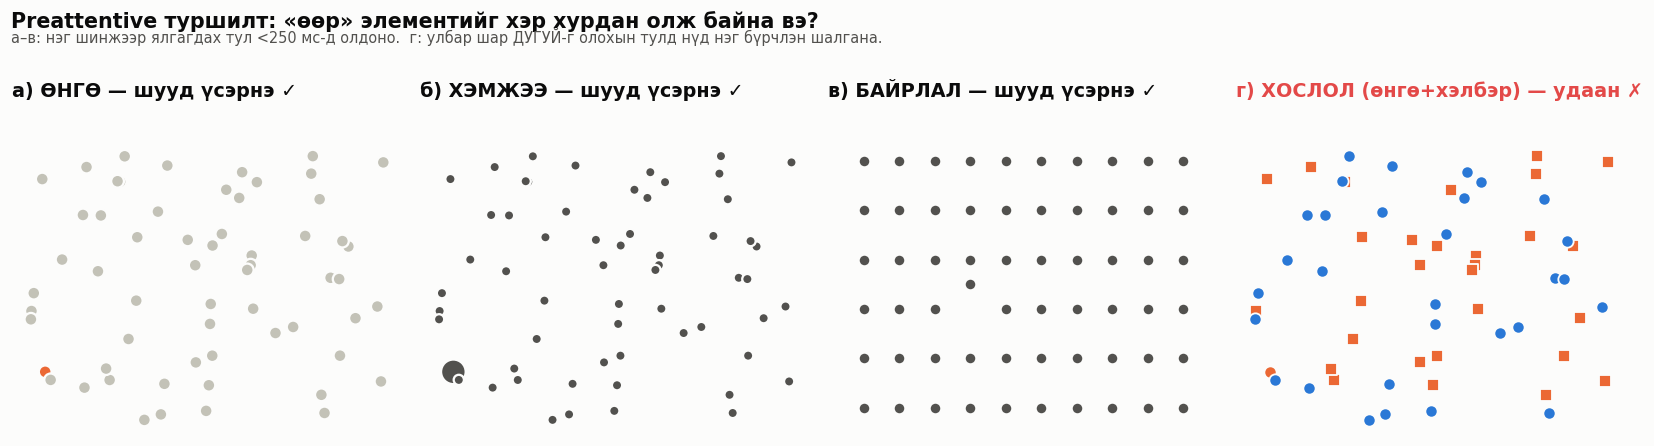

In [6]:
rng = np.random.default_rng(7)
N = 60
xs, ys = rng.uniform(0, 1, N), rng.uniform(0, 1, N)
t = 23  # зорилтот элементийн индекс

fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)

# (a) Өнгө
c = [C['gray']]*N; c[t] = C['orange']
axes[0].scatter(xs, ys, s=70, c=c, edgecolor=C['surface'], linewidth=1.5)
axes[0].set_title('а) ӨНГӨ — шууд үсэрнэ ✓', color=C['ink'])

# (b) Хэмжээ
sz = np.full(N, 45.); sz[t] = 260
axes[1].scatter(xs, ys, s=sz, c=C['ink2'], edgecolor=C['surface'], linewidth=1.5)
axes[1].set_title('б) ХЭМЖЭЭ — шууд үсэрнэ ✓', color=C['ink'])

# (c) Байрлал: эгнээнээс гарсан цэг
gx = np.tile(np.linspace(0.05, 0.95, 10), 6); gy = np.repeat(np.linspace(0.05, 0.95, 6), 10)
gy2 = gy.copy(); gy2[t] += 0.09
axes[2].scatter(gx, gy2, s=60, c=C['ink2'], edgecolor=C['surface'], linewidth=1.5)
axes[2].set_title('в) БАЙРЛАЛ — шууд үсэрнэ ✓', color=C['ink'])

# (d) Хослол: улбар дөрвөлжин + цэнхэр дугуй + НЭГ улбар дугуй
half = N // 2
col = np.array([C['orange']]*half + [C['blue']]*(N-half)); mk = ['s']*half + ['o']*(N-half)
col[t] = C['orange']; mk[t] = 'o'
for x, y, cc, m in zip(xs, ys, col, mk):
    axes[3].scatter(x, y, s=65, c=cc, marker=m, edgecolor=C['surface'], linewidth=1.2)
axes[3].set_title('г) ХОСЛОЛ (өнгө+хэлбэр) — удаан ✗', color=C['red'])

fig.suptitle('Preattentive туршилт: «өөр» элементийг хэр хурдан олж байна вэ?', x=0.01, ha='left',
             fontsize=13.5, fontweight='bold', color=C['ink'], y=1.03)
fig.text(0.01, 0.955, 'а–в: нэг шинжээр ялгагдах тул <250 мс-д олдоно.  г: улбар шар ДУГУЙ-г олохын тулд нүд нэг бүрчлэн шалгана.',
         fontsize=9.5, color=C['ink2'])
plt.tight_layout(); plt.show()

## 3.2 Бүх суваг адил биш: нарийвчлалын эрэмбэ (Cleveland & McGill, 1984; Munzner)
Тоон утгыг хүн дараах сувгаас **буурах нарийвчлалтайгаар** уншдаг:

**Нийтлэг тэнхлэг дээрх байрлал > Урт > Өнцөг/налуу > Талбай > Өнгөний тод/цайвар**

Иймээс **гол хэмжүүрийг (амьд үлдэлтийн %) байрлал/уртад**, ангиллыг өнгөнд, хоёрдогч мэдээллийг (n) хэмжээнд онооно. Доор нэг өгөгдлийг (зэрэг × хүйсээр амьд үлдэлт, 6 утга) 5 өөр сувгаар дүрсэлсэн. «3-р зэргийн эмэгтэй 2-р зэргийн эмэгтэйгээс хэр бага вэ?» гэдгийг аль дээр нь хамгийн амархан хэлж чадаж байна?

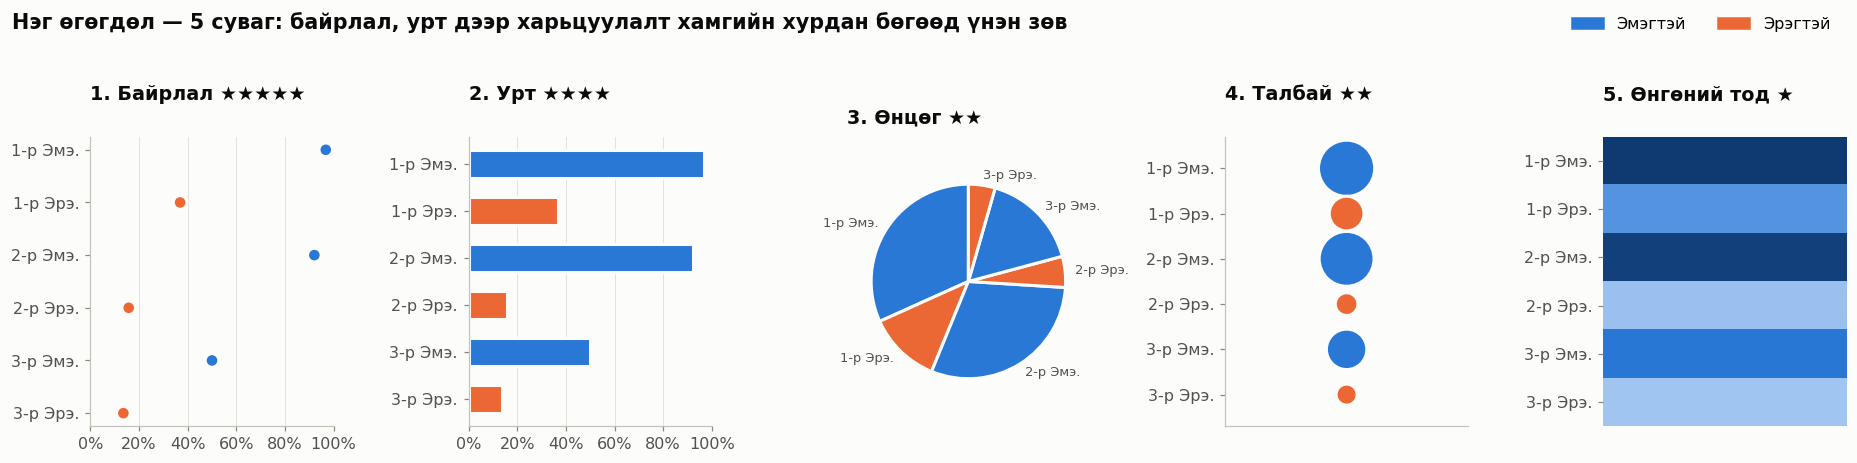

In [7]:
g = df.groupby(['Зэрэг', 'Хүйс'])['Survived'].mean().reset_index()
g['label'] = g['Зэрэг'].astype(str) + '-р ' + g['Хүйс'].str[:3] + '.'
vals, labels = g['Survived'].values, g['label'].values
cols = [SEX_COLOR[s] for s in g['Хүйс']]
idx = np.arange(len(vals))

fig, axes = plt.subplots(1, 5, figsize=(17, 4))
# 1. Байрлал
ax = axes[0]; ax.scatter(vals, idx, s=80, c=cols, zorder=3, edgecolor=C['surface'], linewidth=2)
ax.set_yticks(idx, labels); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PCT)
ax.grid(axis='x'); ax.grid(axis='y', visible=False); ax.set_title('1. Байрлал ★★★★★')
# 2. Урт
ax = axes[1]; ax.barh(idx, vals, color=cols, height=0.6, edgecolor=C['surface'], linewidth=2)
ax.set_yticks(idx, labels); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PCT)
ax.grid(axis='x'); ax.grid(axis='y', visible=False); ax.set_title('2. Урт ★★★★')
# 3. Өнцөг
ax = axes[2]; ax.pie(vals, colors=cols, labels=labels, wedgeprops=dict(edgecolor=C['surface'], linewidth=2),
                     textprops=dict(fontsize=8.5, color=C['ink2']), startangle=90)
ax.set_title('3. Өнцөг ★★')
# 4. Талбай
ax = axes[3]; ax.scatter(np.zeros(6), idx, s=vals*1400, c=cols, edgecolor=C['surface'], linewidth=2)
ax.set_yticks(idx, labels); ax.invert_yaxis(); ax.set_xticks([]); ax.set_xlim(-1, 1); ax.set_ylim(5.7, -0.7)
ax.grid(False); ax.set_title('4. Талбай ★★')
# 5. Өнгөний тод
ax = axes[4]; ax.imshow(vals.reshape(-1, 1), cmap=SEQUENTIAL, vmin=0, vmax=1, aspect='auto')
ax.set_yticks(idx, labels); ax.set_xticks([]); ax.grid(False); ax.set_title('5. Өнгөний тод ★')
for s in ax.spines.values(): s.set_visible(False)

fig.suptitle('Нэг өгөгдөл — 5 суваг: байрлал, урт дээр харьцуулалт хамгийн хурдан бөгөөд үнэн зөв',
             x=0.01, ha='left', fontsize=13.5, fontweight='bold', color=C['ink'], y=1.04)
fig.legend(handles=[Patch(color=v, label=k) for k, v in SEX_COLOR.items()], loc='upper right',
           ncol=2, bbox_to_anchor=(0.99, 1.06))
plt.tight_layout(); plt.show()

## 3.3 Хүний харааны онцлогийг ашигласан дүрмүүд (энэ notebook-д мөрдсөн)

| Харааны онцлог | Дүрэм | Хэрэгжүүлэлт |
|---|---|---|
| **Pop-out (preattentive)** | Нэг графикт нэг гол мессеж → нэг онцлох суваг | Гол бүлэг өнгөтэй, бусад нь саарал |
| **Ажлын санах ой ~4 зүйл** | Ангиллын өнгө ≤ 4, legend-ээс шууд шошгыг илүүд үзэх | Хүйс = 2 өнгө, шошгыг шугамын үзүүрт |
| **Gestalt: ойр байдал, төстэй байдал** | Харьцуулах зүйлсийг хажууд нь, ижил өнгөөр | Хүйсийг бүх графикт ижил өнгөөр (тогтвортой mapping) |
| **Эрэмбийг гэрэлтүүлгээр мэдэрдэг** | Эрэмбэтэй өгөгдөлд нэг өнгөний цайвар→бараан | 1-р зэрэг = бараан, 3-р = цайвар |
| **Харьцангуй ялгааг мэдэрдэг (Weber)** | Лавлах шугам өгөх | Нийт дундаж 38.4%-ийн тасархай шугам |
| **~8% эрэгтэйчүүд өнгөний харалган** | Улаан/ногоон хосоос зайлсхийх, CVD-д шалгах | Цэнхэр/улбар шар (ΔE 24.7, шалгагдсан) |
| **Анхаарал зүүн дээд буланд эхэлдэг** | Гарчиг = олдвор (*action title*) | «Эмэгтэйчүүд 4 дахин их амьд үлдсэн» гэх мэт |
| **Тэнхлэг, сүлжээ бол туслах** | Сүлжээ шугам нимгэн, саарал | `grid` 0.6px, цайвар саарал |

---
# 4. Хэрэгжүүлэлт: зорилго бүрийн гол олдвор

## З1. Амьд үлдэх — «Эмэгтэй, хүүхэд түрүүлж» дүрэм
**Mapping:** насны бүлэг → X-байрлал (эрэмбэ) · амьд үлдэлт → Y-байрлал · хүйс → өнгө (hue) · бүлгийн хэмжээ → цэгийн хэмжээ · нийт дундаж → лавлах шугам.

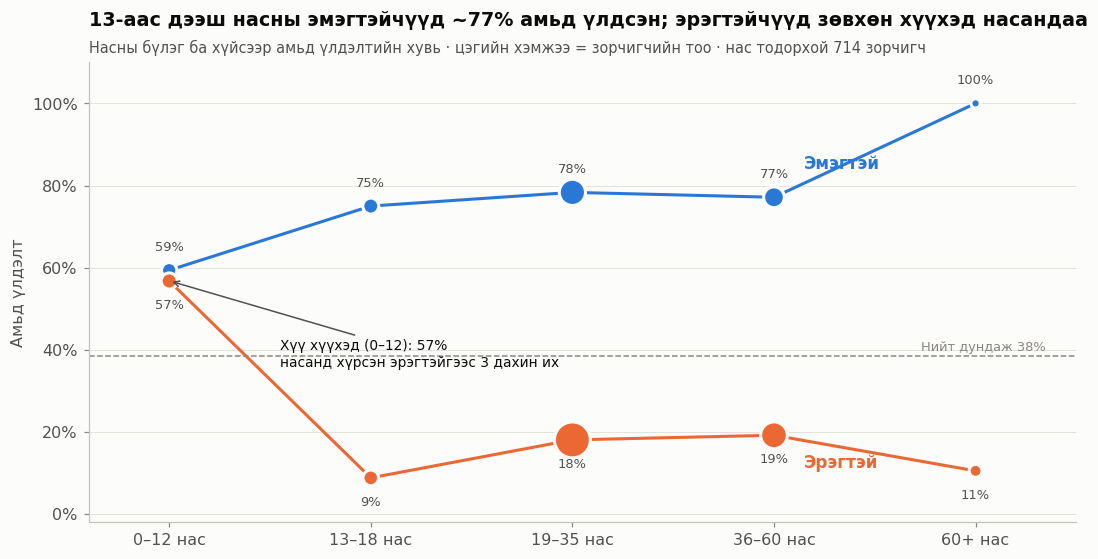

In [8]:
a = (df.dropna(subset=['Насны_бүлэг'])
       .groupby(['Хүйс', 'Насны_бүлэг'], observed=True)['Survived'].agg(['mean', 'size']).reset_index())

fig, ax = plt.subplots(figsize=(10, 5.2))
x = {k: i for i, k in enumerate(AGE_ORDER)}
for sex, sub in a.groupby('Хүйс'):
    xx = sub['Насны_бүлэг'].map(x).astype(int)
    ax.plot(xx, sub['mean'], color=SEX_COLOR[sex], lw=2, zorder=2)
    ax.scatter(xx, sub['mean'], s=sub['size']*2.2 + 30, color=SEX_COLOR[sex], zorder=3,
               edgecolor=C['surface'], linewidth=2)
    last = sub.iloc[-2]  # 60+ бүлэг жижиг тул шошгыг 36–60 дээр
    ax.text(x[last['Насны_бүлэг']] + 0.15, last['mean'] + (0.07 if sex == 'Эмэгтэй' else -0.08),
            sex, color=SEX_COLOR[sex], fontweight='bold', fontsize=11)
    for _, r in sub.iterrows():
        ax.annotate(f"{r['mean']:.0%}", (x[r['Насны_бүлэг']], r['mean']), textcoords='offset points',
                    xytext=(0, 13 if sex == 'Эмэгтэй' else -18), ha='center', fontsize=8.5, color=C['ink2'])

ax.axhline(OVERALL, ls='--', lw=1, color=C['muted'])
ax.text(4.35, OVERALL + 0.015, f'Нийт дундаж {OVERALL:.0%}', color=C['muted'], fontsize=8.5, ha='right')
# Онцлох: хүү хүүхэд
ax.annotate('Хүү хүүхэд (0–12): 57%\nнасанд хүрсэн эрэгтэйгээс 3 дахин их',
            xy=(0, 0.568), xytext=(0.55, 0.36), fontsize=9, color=C['ink'],
            arrowprops=dict(arrowstyle='->', color=C['ink2'], lw=1))
ax.set_xticks(range(5), [f'{k} нас' for k in AGE_ORDER]); ax.set_xlim(-0.4, 4.5)
ax.set_ylim(-0.02, 1.1); ax.yaxis.set_major_formatter(PCT); ax.set_ylabel('Амьд үлдэлт')
ax.set_title('13-аас дээш насны эмэгтэйчүүд ~77% амьд үлдсэн; эрэгтэйчүүд зөвхөн хүүхэд насандаа')
subtitle(ax, 'Насны бүлэг ба хүйсээр амьд үлдэлтийн хувь · цэгийн хэмжээ = зорчигчийн тоо · нас тодорхой 714 зорчигч')
plt.tight_layout(); plt.show()

## З2. Нийгмийн давхарга — бүхээгийн зэрэг амьд үлдэлтийг шийдсэн үү?
**Mapping (зүүн):** зэрэг → байрлал + цайвар→бараан (эрэмбэ) · амьд үлдэлт → баганын урт.
**Mapping (баруун):** зэрэг × хүйс → матрицын байрлал · амьд үлдэлт → **diverging өнгө**, төв нь нийт дундаж (38%) — цэнхэр = дунджаас дээш, улаан = доош.

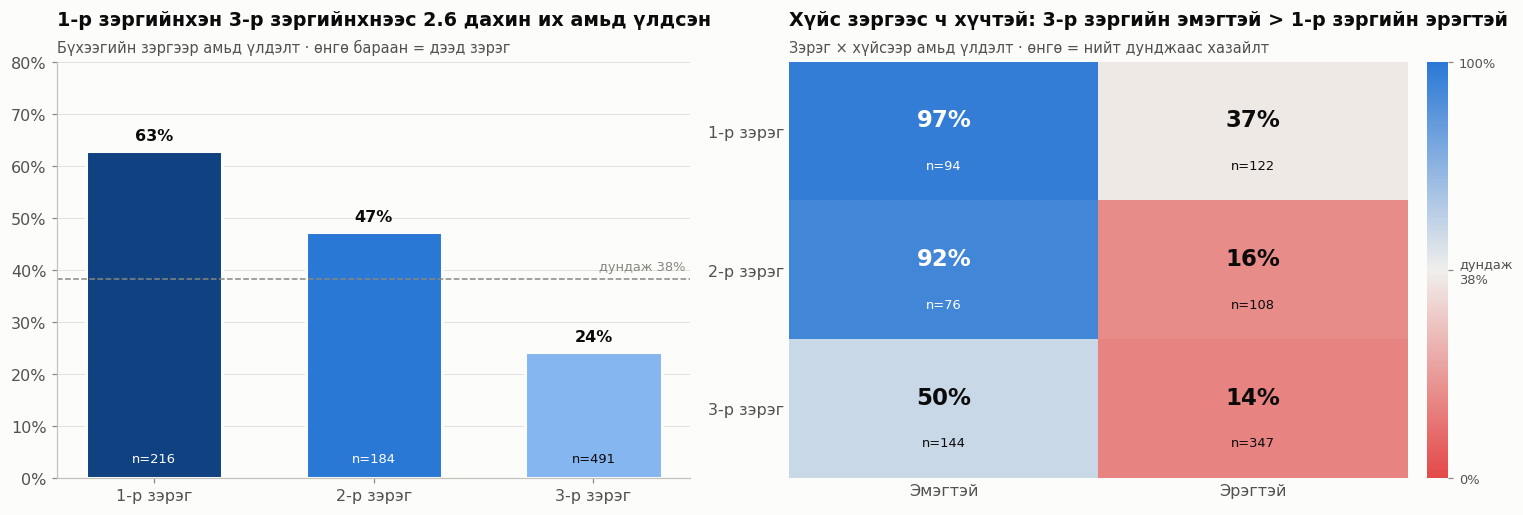

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1, 1.05]})

# Зүүн: зэргээр
c1 = df.groupby('Зэрэг')['Survived'].agg(['mean', 'size'])
bars = ax1.bar([f'{i}-р зэрэг' for i in c1.index], c1['mean'], color=[CLASS_COLOR[i] for i in c1.index],
               width=0.62, edgecolor=C['surface'], linewidth=2)
for b, (m, n) in zip(bars, c1.values):
    ax1.text(b.get_x() + b.get_width()/2, m + 0.02, f'{m:.0%}', ha='center', fontweight='bold', color=C['ink'])
    ax1.text(b.get_x() + b.get_width()/2, 0.03, f'n={int(n)}', ha='center', fontsize=8.5, color=text_on(b.get_facecolor()))
ax1.axhline(OVERALL, ls='--', lw=1, color=C['muted'])
ax1.text(2.42, OVERALL + 0.015, f'дундаж {OVERALL:.0%}', color=C['muted'], fontsize=8.5, ha='right')
ax1.set_ylim(0, 0.8); ax1.yaxis.set_major_formatter(PCT)
ax1.set_title('1-р зэргийнхэн 3-р зэргийнхнээс 2.6 дахин их амьд үлдсэн')
subtitle(ax1, 'Бүхээгийн зэргээр амьд үлдэлт · өнгө бараан = дээд зэрэг')

# Баруун: diverging heatmap 
pv = df.pivot_table(index='Зэрэг_нэр', columns='Хүйс', values='Survived', aggfunc='mean')[['Эмэгтэй', 'Эрэгтэй']]
nv = df.pivot_table(index='Зэрэг_нэр', columns='Хүйс', values='Survived', aggfunc='size')[['Эмэгтэй', 'Эрэгтэй']]
norm = TwoSlopeNorm(vmin=0, vcenter=OVERALL, vmax=1)
im = ax2.imshow(pv.values, cmap=DIVERGING, norm=norm, aspect='auto')
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        v = pv.values[i, j]; fc = DIVERGING(norm(v))
        tc = text_on('#%02x%02x%02x' % tuple(int(255*c) for c in fc[:3]))
        ax2.text(j, i - 0.08, f'{v:.0%}', ha='center', va='center', fontsize=15, fontweight='bold', color=tc)
        ax2.text(j, i + 0.25, f'n={nv.values[i, j]}', ha='center', va='center', fontsize=8.5, color=tc)
ax2.set_xticks([0, 1], pv.columns); ax2.set_yticks(range(3), pv.index); ax2.grid(False)
ax2.tick_params(length=0)
for s in ax2.spines.values(): s.set_visible(False)
cb = plt.colorbar(im, ax=ax2, fraction=0.04, pad=0.03, ticks=[0, OVERALL, 1])
cb.ax.set_yticklabels(['0%', f'дундаж\n{OVERALL:.0%}', '100%'], fontsize=8.5, color=C['ink2']); cb.outline.set_visible(False)
ax2.set_title('Хүйс зэргээс ч хүчтэй: 3-р зэргийн эмэгтэй > 1-р зэргийн эрэгтэй')
subtitle(ax2, 'Зэрэг × хүйсээр амьд үлдэлт · өнгө = нийт дунджаас хазайлт')
plt.tight_layout(); plt.show()

Төлбөр (`Fare`) нь зэргийн тоон илэрхийлэл. Хэт хазайлттай (0–512 фунт) тул **лог масштаб** дээр байрлуулна; амьд үлдсэн/үлдээгүйг онцлох өнгө vs саарлаар:

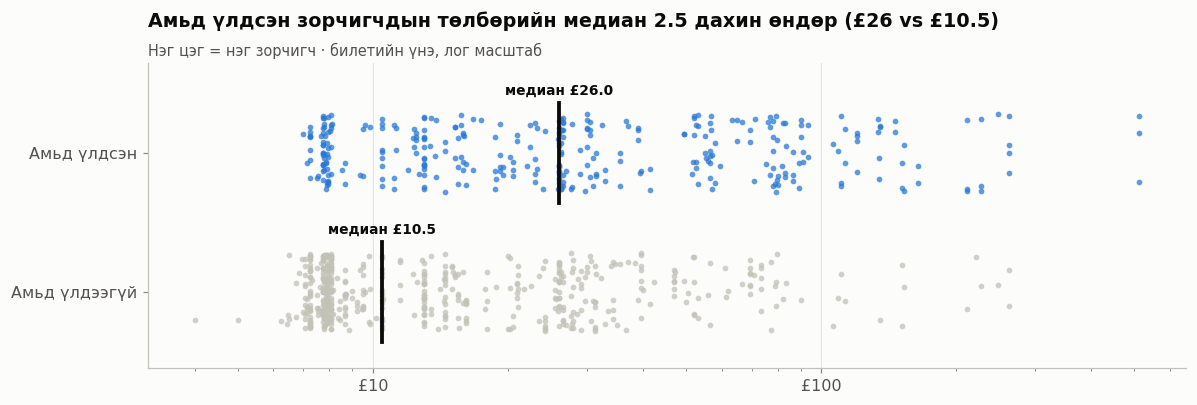

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.8))
rng = np.random.default_rng(1)
for k, (surv, color, name) in enumerate([(0, C['gray'], 'Амьд үлдээгүй'), (1, C['blue'], 'Амьд үлдсэн')]):
    sub = df[(df['Survived'] == surv) & (df['Fare'] > 0)]
    ax.scatter(sub['Fare'], k + rng.uniform(-0.28, 0.28, len(sub)), s=14, color=color, alpha=0.75, lw=0)
    med = sub['Fare'].median()
    ax.plot([med, med], [k - 0.36, k + 0.36], color=C['ink'], lw=2.5)
    ax.text(med, k + 0.42, f'медиан £{med:.1f}', ha='center', fontsize=9, color=C['ink'], fontweight='bold')
ax.set_xscale('log'); ax.set_yticks([0, 1], ['Амьд үлдээгүй', 'Амьд үлдсэн']); ax.set_ylim(-0.55, 1.65)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'£{v:g}'))
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('Амьд үлдсэн зорчигчдын төлбөрийн медиан 2.5 дахин өндөр (£26 vs £10.5)')
subtitle(ax, 'Нэг цэг = нэг зорчигч · билетийн үнэ, лог масштаб')
plt.tight_layout(); plt.show()

## З3. Гэр бүлийн нөлөө — «алтан дундаж» байсан уу?
**Mapping:** гэр бүлийн хэмжээ → X-байрлал · амьд үлдэлт → Y-байрлал · **зорчигчийн тоо → цэгийн хэмжээ** (жижиг бүлгийн хувь найдваргүй гэдгийг нүд шууд мэдэрнэ) · «Жижиг (2–4)» → **онцлох өнгө**, бусад саарал.

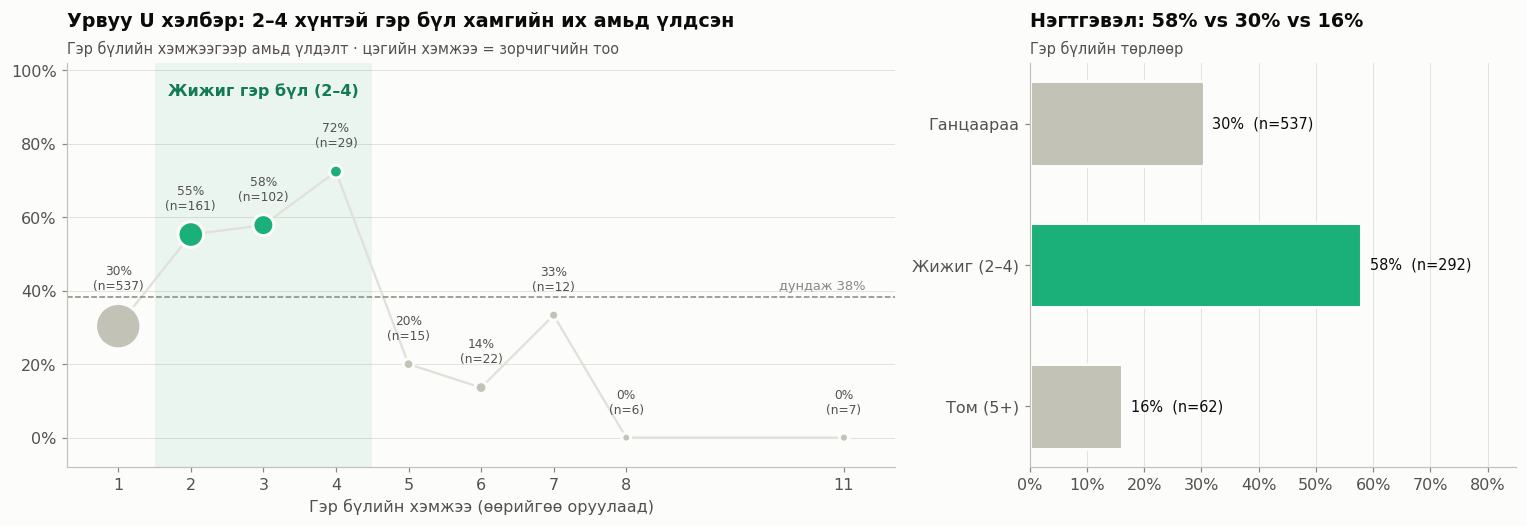

In [11]:
f = df.groupby('Гэр_бүл')['Survived'].agg(['mean', 'size']).reset_index()
colors = [C['aqua'] if 2 <= s <= 4 else C['gray'] for s in f['Гэр_бүл']]

fig, (ax, axb) = plt.subplots(1, 2, figsize=(14, 4.9), gridspec_kw={'width_ratios': [1.7, 1]})
ax.axvspan(1.5, 4.5, color=C['aqua'], alpha=0.08, lw=0)
ax.plot(f['Гэр_бүл'], f['mean'], color=C['light_gray'], lw=1.5, zorder=1)
ax.scatter(f['Гэр_бүл'], f['mean'], s=f['size']*1.6 + 25, c=colors, zorder=3, edgecolor=C['surface'], linewidth=2)
for _, r in f.iterrows():
    ax.annotate(f"{r['mean']:.0%}\n(n={int(r['size'])})", (r['Гэр_бүл'], r['mean']), textcoords='offset points',
                xytext=(0, 16 if r['size'] < 200 else 24), ha='center', fontsize=8, color=C['ink2'])
ax.axhline(OVERALL, ls='--', lw=1, color=C['muted'])
ax.text(11.3, OVERALL + 0.02, f'дундаж {OVERALL:.0%}', color=C['muted'], fontsize=8.5, ha='right')
ax.text(3, 0.93, 'Жижиг гэр бүл (2–4)', ha='center', color='#127a55', fontweight='bold')
ax.set_xticks(f['Гэр_бүл']); ax.set_xlabel('Гэр бүлийн хэмжээ (өөрийгөө оруулаад)')
ax.set_ylim(-0.08, 1.02); ax.yaxis.set_major_formatter(PCT); ax.set_xlim(0.3, 11.7)
ax.set_title('Урвуу U хэлбэр: 2–4 хүнтэй гэр бүл хамгийн их амьд үлдсэн')
subtitle(ax, 'Гэр бүлийн хэмжээгээр амьд үлдэлт · цэгийн хэмжээ = зорчигчийн тоо')

ft = df.groupby('Гэр_бүлийн_төрөл', observed=True)['Survived'].agg(['mean', 'size'])
bars = axb.barh(ft.index.astype(str), ft['mean'], color=[C['gray'], C['aqua'], C['gray']],
                height=0.6, edgecolor=C['surface'], linewidth=2)
for b, (m, n) in zip(bars, ft.values):
    axb.text(m + 0.015, b.get_y() + b.get_height()/2, f'{m:.0%}  (n={int(n)})', va='center', color=C['ink'], fontsize=9.5)
axb.invert_yaxis(); axb.set_xlim(0, 0.85); axb.xaxis.set_major_formatter(PCT)
axb.grid(axis='x'); axb.grid(axis='y', visible=False)
axb.set_title('Нэгтгэвэл: 58% vs 30% vs 16%'); subtitle(axb, 'Гэр бүлийн төрлөөр')
plt.tight_layout(); plt.show()

---
# 5. Практик харьцуулалт

## 5.1 Буруу vs зөв арга
Гурван түгээмэл алдааг ижил өгөгдөл дээр харьцуулна. Алдаа бүр **нэг асуултын** зөрчил:

| # | Буруу | Аль асуултын алдаа | Зөв |
|---|---|---|---|
| А | Амьд үлдсэн хүмүүсийн **тоог** pie-аар | *Юуг* — бүлгийн хэмжээ ялгаатай үед тоо биш **хувь** хэрэгтэй; *Хэрхэн* — өнцөг нарийвчлал муу | Амьд үлдэлтийн **хувийг** баганын уртаар |
| Б | Солонго (jet) өнгөний шкал | *Хэрхэн* — солонгод «дундаж» цэг байхгүй, шар өнгө хуурамч хил үүсгэнэ | Diverging: дунджаар төвлөрсөн 2 өнгө |
| В | Улаан/ногоон + бүх баганыг өөр өнгөөр | *Хэрхэн* — өнгөний харалган хүн ялгахгүй, preattentive сувгийг дэмий үрнэ | Онцлох өнгө + саарал, CVD-д шалгасан |

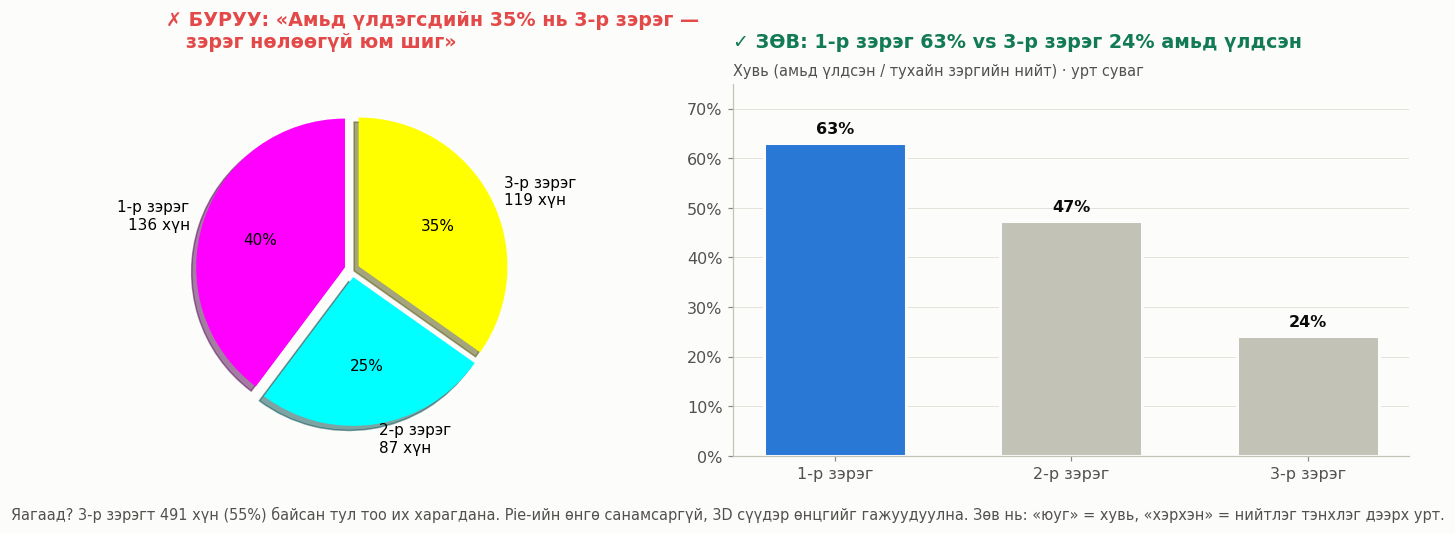

In [12]:
# ── А: Тоо + pie  vs  Хувь + багана ──────────────────────────
fig, (axw, axr) = plt.subplots(1, 2, figsize=(13, 4.6))
cnt = df[df.Survived == 1].groupby('Зэрэг').size()
axw.pie(cnt, labels=[f'{i}-р зэрэг\n{v} хүн' for i, v in cnt.items()], autopct='%1.0f%%',
        colors=['#ff00ff', '#00ffff', '#ffff00'], startangle=90, explode=[0.05]*3, shadow=True,
        textprops=dict(fontsize=10))
axw.set_title('✗ БУРУУ: «Амьд үлдэгсдийн 35% нь 3-р зэрэг —\n   зэрэг нөлөөгүй юм шиг»', color=C['red'])

rate = df.groupby('Зэрэг')['Survived'].mean()
bars = axr.bar([f'{i}-р зэрэг' for i in rate.index], rate, color=[C['blue'], C['gray'], C['gray']],
               width=0.6, edgecolor=C['surface'], linewidth=2)
for b, v in zip(bars, rate):
    axr.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.0%}', ha='center', fontweight='bold', color=C['ink'])
axr.set_ylim(0, 0.75); axr.yaxis.set_major_formatter(PCT)
axr.set_title('✓ ЗӨВ: 1-р зэрэг 63% vs 3-р зэрэг 24% амьд үлдсэн', color='#127a55')
subtitle(axr, 'Хувь (амьд үлдсэн / тухайн зэргийн нийт) · урт суваг')
fig.text(0.01, -0.04, 'Яагаад? 3-р зэрэгт 491 хүн (55%) байсан тул тоо их харагдана. Pie-ийн өнгө санамсаргүй, 3D сүүдэр өнцгийг гажуудуулна. '
         'Зөв нь: «юуг» = хувь, «хэрхэн» = нийтлэг тэнхлэг дээрх урт.', fontsize=9.5, color=C['ink2'])
plt.tight_layout(); plt.show()

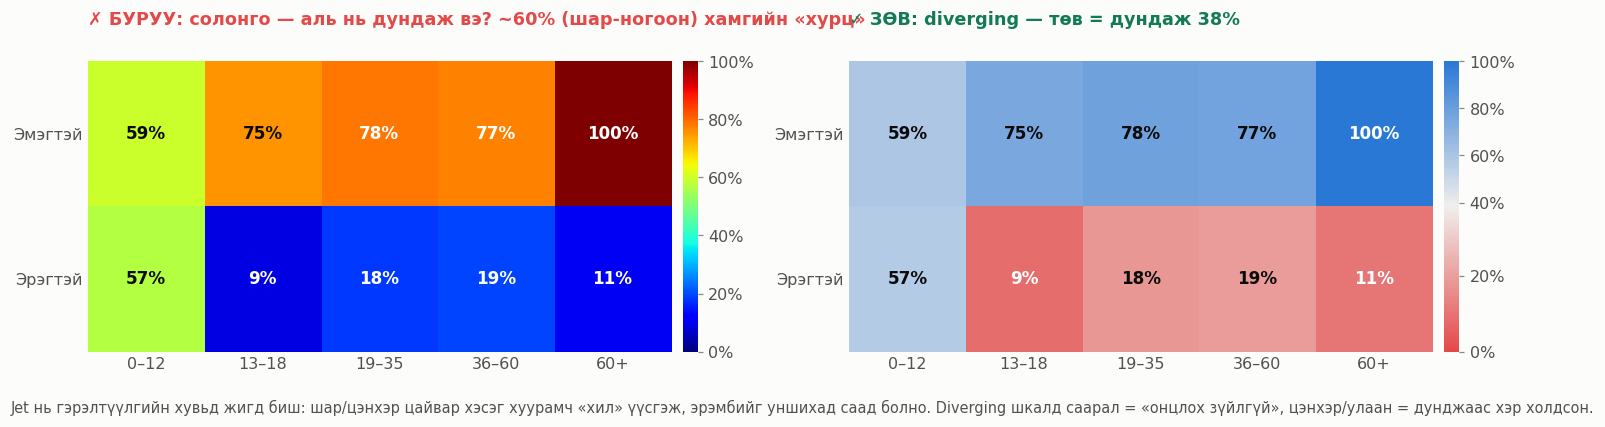

In [13]:
# ── Б: Солонго (jet)  vs  Diverging ─────────────────────────
hm = (df.dropna(subset=['Насны_бүлэг'])
        .pivot_table(index='Хүйс', columns='Насны_бүлэг', values='Survived', aggfunc='mean', observed=True))
fig, (axw, axr) = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, cmap, norm, ttl, tc in [
        (axw, 'jet', None, '✗ БУРУУ: солонго — аль нь дундаж вэ? ~60% (шар-ногоон) хамгийн «хурц»', C['red']),
        (axr, DIVERGING, TwoSlopeNorm(vmin=0, vcenter=OVERALL, vmax=1), f'✓ ЗӨВ: diverging — төв = дундаж {OVERALL:.0%}', '#127a55')]:
    im = ax.imshow(hm.values, cmap=cmap, norm=norm, vmin=None if norm else 0, vmax=None if norm else 1, aspect='auto')
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            v = hm.values[i, j]
            fc = im.cmap(im.norm(v)); tcol = text_on('#%02x%02x%02x' % tuple(int(255*c) for c in fc[:3]))
            ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=11, fontweight='bold', color=tcol)
    ax.set_xticks(range(5), [f'{k}' for k in hm.columns]); ax.set_yticks([0, 1], hm.index)
    ax.grid(False); ax.tick_params(length=0); ax.set_title(ttl, color=tc, fontsize=11.5)
    for s in ax.spines.values(): s.set_visible(False)
    cb = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.ax.yaxis.set_major_formatter(PCT); cb.outline.set_visible(False)
fig.text(0.01, -0.06, 'Jet нь гэрэлтүүлгийн хувьд жигд биш: шар/цэнхэр цайвар хэсэг хуурамч «хил» үүсгэж, эрэмбийг уншихад саад болно. '
         'Diverging шкалд саарал = «онцлох зүйлгүй», цэнхэр/улаан = дунджаас хэр холдсон.', fontsize=9.5, color=C['ink2'])
plt.tight_layout(); plt.show()

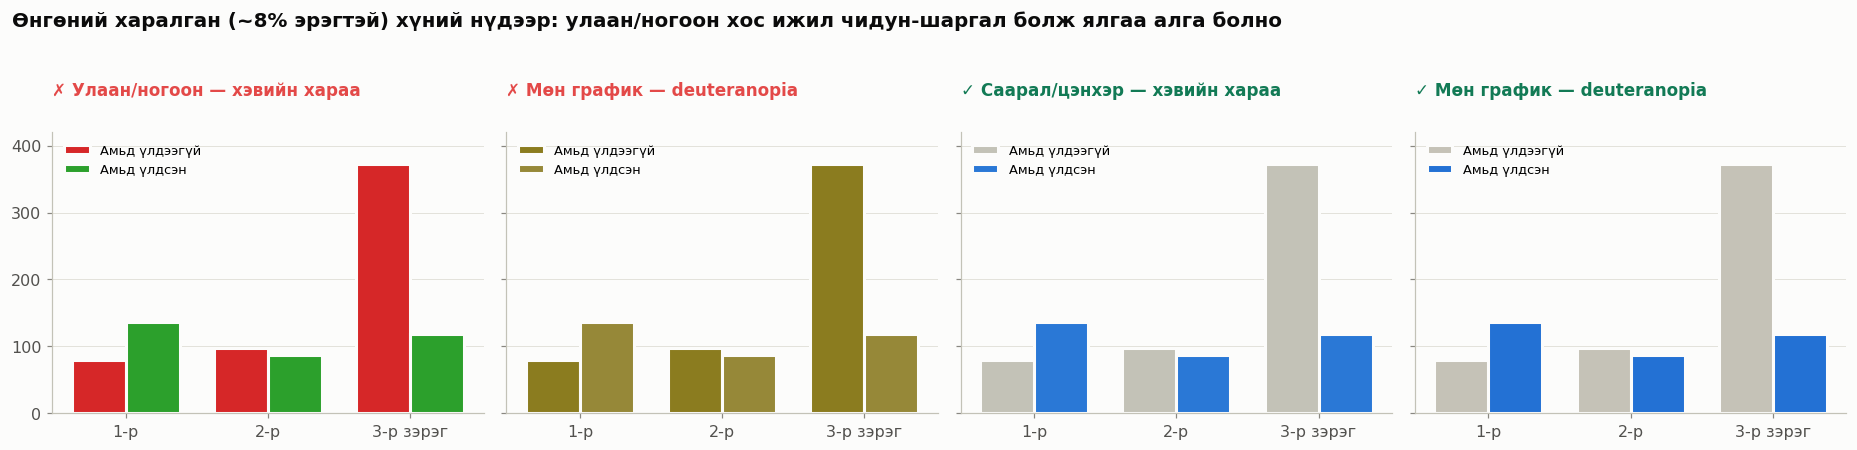

In [14]:
# ── В: Улаан/ногоон  vs  CVD-д тэсвэртэй онцлол — өнгөний харалган (deuteranopia) симуляцтай ──
M_DEUT = np.array([[0.367322, 0.860646, -0.227968],   # Machado et al. (2009), severity 1.0
                   [0.280085, 0.672501,  0.047413],
                   [-0.011820, 0.042940, 0.968881]])
def _lin(c): c = np.asarray(c); return np.where(c <= 0.04045, c/12.92, ((c+0.055)/1.055)**2.4)
def _srgb(c): c = np.clip(c, 0, 1); return np.where(c <= 0.0031308, 12.92*c, 1.055*c**(1/2.4) - 0.055)
def deut(hex_color): return tuple(_srgb(M_DEUT @ _lin(to_rgb(hex_color))))

ct = df.groupby(['Зэрэг', 'Survived']).size().unstack()
def draw(ax, c_died, c_surv, title, tcolor, sim=False):
    cd, cs = (deut(c_died), deut(c_surv)) if sim else (c_died, c_surv)
    xx = np.arange(3); w = 0.38
    ax.bar(xx - w/2, ct[0], w, color=cd, edgecolor=C['surface'], linewidth=2, label='Амьд үлдээгүй')
    ax.bar(xx + w/2, ct[1], w, color=cs, edgecolor=C['surface'], linewidth=2, label='Амьд үлдсэн')
    ax.set_xticks(xx, ['1-р', '2-р', '3-р зэрэг']); ax.set_ylim(0, 420)
    ax.set_title(title, color=tcolor, fontsize=11); ax.legend(loc='upper left', fontsize=8.5)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
draw(axes[0], '#d62728', '#2ca02c', '✗ Улаан/ногоон — хэвийн хараа', C['red'])
draw(axes[1], '#d62728', '#2ca02c', '✗ Мөн график — deuteranopia', C['red'], sim=True)
draw(axes[2], C['gray'], C['blue'], '✓ Саарал/цэнхэр — хэвийн хараа', '#127a55')
draw(axes[3], C['gray'], C['blue'], '✓ Мөн график — deuteranopia', '#127a55', sim=True)
fig.suptitle('Өнгөний харалган (~8% эрэгтэй) хүний нүдээр: улаан/ногоон хос ижил чидун-шаргал болж ялгаа алга болно',
             x=0.01, ha='left', fontsize=13, fontweight='bold', color=C['ink'], y=1.04)
plt.tight_layout(); plt.show()

## 5.2 Энгийн хүснэгт vs Visual mapping
**Асуулт:** «Зэрэг × хүйс × насны бүлгээр аль бүлэг хамгийн их / бага амьд үлдсэн бэ? Ерөнхий хэв маяг юу вэ?»

### (а) Энгийн хүснэгт — 30 тоо

In [15]:
full = (df.dropna(subset=['Насны_бүлэг'])
          .groupby(['Зэрэг_нэр', 'Хүйс', 'Насны_бүлэг'], observed=False)['Survived'].agg(['mean', 'size']))
tbl = full['mean'].unstack('Насны_бүлэг')
n_tbl = full['size'].unstack('Насны_бүлэг')
display(tbl.round(3))
print('Хүснэгтээс хариулт олохын тулд 30 нүдийг нэг бүрчлэн уншиж, толгойдоо харьцуулах шаардлагатай (serial search).')

Насны_бүлэг         0–12  13–18  19–35  36–60    60+
Зэрэг_нэр Хүйс                                      
1-р зэрэг Эмэгтэй  0.000  1.000  0.972  0.972  1.000
          Эрэгтэй  1.000  0.500  0.500  0.370  0.083
2-р зэрэг Эмэгтэй  1.000  1.000  0.925  0.850    NaN
          Эрэгтэй  1.000  0.000  0.074  0.037  0.333
3-р зэрэг Эмэгтэй  0.478  0.550  0.500  0.143  1.000
          Эрэгтэй  0.360  0.077  0.156  0.068  0.000

Хүснэгтээс хариулт олохын тулд 30 нүдийг нэг бүрчлэн уншиж, толгойдоо харьцуулах шаардлагатай (serial search).


### (б) Visual mapping — ижил 30 утга, байрлал + diverging өнгө + шошго

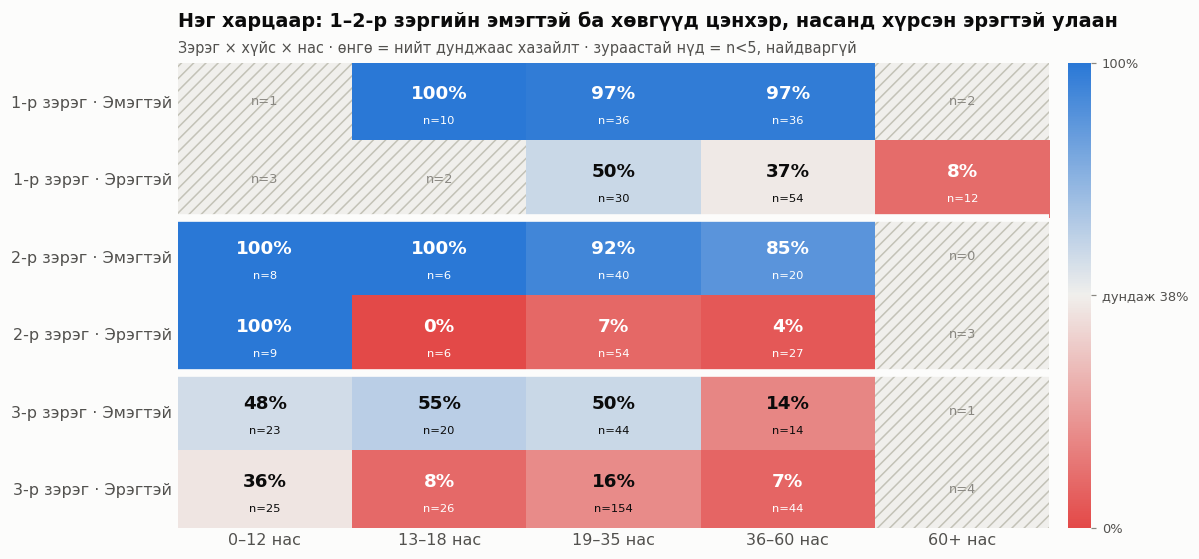

In [16]:
fig, ax = plt.subplots(figsize=(11, 5.2))
norm = TwoSlopeNorm(vmin=0, vcenter=OVERALL, vmax=1)
vals = tbl.values.astype(float); nn = n_tbl.values
masked = np.where(nn >= 5, vals, np.nan)                 # n<5 бүлгийн хувь найдваргүй → саарлаар
im = ax.imshow(masked, cmap=DIVERGING, norm=norm, aspect='auto')
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        if nn[i, j] < 5:
            ax.add_patch(plt.Rectangle((j-0.5, i-0.5), 1, 1, facecolor=C['mid'], hatch='///', edgecolor=C['gray'], lw=0))
            ax.text(j, i, f'n={int(nn[i, j])}', ha='center', va='center', fontsize=8.5, color=C['muted'])
            continue
        fc = DIVERGING(norm(vals[i, j])); tc = text_on('#%02x%02x%02x' % tuple(int(255*c) for c in fc[:3]))
        ax.text(j, i - 0.1, f'{vals[i, j]:.0%}', ha='center', va='center', fontsize=12, fontweight='bold', color=tc)
        ax.text(j, i + 0.25, f'n={int(nn[i, j])}', ha='center', va='center', fontsize=7.5, color=tc)
for y in [1.5, 3.5]: ax.axhline(y, color=C['surface'], lw=5)   # Gestalt: зэргээр бүлэглэх
ax.set_xticks(range(5), [f'{k} нас' for k in tbl.columns]); ax.set_yticks(range(6), [f'{a} · {b}' for a, b in tbl.index])
ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
cb = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02, ticks=[0, OVERALL, 1])
cb.ax.set_yticklabels(['0%', f'дундаж {OVERALL:.0%}', '100%'], fontsize=8.5); cb.outline.set_visible(False)
ax.set_title('Нэг харцаар: 1–2-р зэргийн эмэгтэй ба хөвгүүд цэнхэр, насанд хүрсэн эрэгтэй улаан')
subtitle(ax, 'Зэрэг × хүйс × нас · өнгө = нийт дунджаас хазайлт · зураастай нүд = n<5, найдваргүй')
plt.tight_layout(); plt.show()

In [17]:
# Хүснэгтээс олдвор гаргахыг автоматжуулбал хэдэн алхам шаардагдаж байгааг харьцуулъя
valid = full[full['size'] >= 5]
best, worst = valid['mean'].idxmax(), valid['mean'].idxmin()
print(f'Хамгийн өндөр: {best} → {valid.loc[best, "mean"]:.0%}')
print(f'Хамгийн бага : {worst} → {valid.loc[worst, "mean"]:.0%}')

cmp = pd.DataFrame({
    'Шалгуур': ['Хамгийн их/бага бүлгийг олох', 'Ерөнхий хэв маяг (хүйс > зэрэг > нас)', 'Дунджаас дээш/доош',
                'Найдваргүй жижиг бүлгийг анзаарах', 'Яг тодорхой утгыг унших', 'Танин мэдэхүйн ачаалал'],
    'Энгийн хүснэгт': ['30 нүдийг дараалан уншина (serial)', 'Толгойдоо харьцуулах — алдах магадлалтай',
                       'Нүд бүрийг 0.384-тэй тулгана', 'n тусдаа хүснэгтэд — анзаарахгүй', '✓ Маш нарийн', 'Өндөр (ажлын санах ой ~4 зүйл)'],
    'Visual mapping': ['Хамгийн бараан цэнхэр/улаан шууд үсэрнэ (pop-out)', 'Цэнхэр багана vs улаан мөр — нэг харцаар',
                       'Өнгөний чиглэл (цэнхэр/улаан) шууд хэлнэ', 'Зураастай саарал нүд — шууд анзаарагдана',
                       '✓ Шошготой тул алдагдахгүй', 'Бага (preattentive + Gestalt бүлэглэл)'],
})
display(cmp.style.hide(axis='index').set_properties(**{'text-align': 'left', 'font-size': '12px'}))

Хамгийн өндөр: ('1-р зэрэг', 'Эмэгтэй', '13–18') → 100%
Хамгийн бага : ('2-р зэрэг', 'Эрэгтэй', '13–18') → 0%


Шалгуур,Энгийн хүснэгт,Visual mapping
Хамгийн их/бага бүлгийг олох,30 нүдийг дараалан уншина (serial),Хамгийн бараан цэнхэр/улаан шууд үсэрнэ (pop-out)
Ерөнхий хэв маяг (хүйс > зэрэг > нас),Толгойдоо харьцуулах — алдах магадлалтай,Цэнхэр багана vs улаан мөр — нэг харцаар
Дунджаас дээш/доош,Нүд бүрийг 0.384-тэй тулгана,Өнгөний чиглэл (цэнхэр/улаан) шууд хэлнэ
Найдваргүй жижиг бүлгийг анзаарах,n тусдаа хүснэгтэд — анзаарахгүй,Зураастай саарал нүд — шууд анзаарагдана
Яг тодорхой утгыг унших,✓ Маш нарийн,✓ Шошготой тул алдагдахгүй
Танин мэдэхүйн ачаалал,Өндөр (ажлын санах ой ~4 зүйл),Бага (preattentive + Gestalt бүлэглэл)


**Дүгнэлт:** Хүснэгт нь *яг утгыг хайх* (lookup) ажилд сайн, харин *хэв маяг, харьцуулалт, гажуудал* олох ажилд visual mapping давуу. Хамгийн сайн шийдэл бол хоёуланг нь хослуулах — график дээр сонгомол шошго (утга), доор нь хүснэгт хавсаргах.

---
# 6. Гол олдворууд — нэгтгэсэн самбар
Гарчиг бүр **олдвор өөрөө** (action title). Гурван график ижил mapping дүрэмтэй: Y = амьд үлдэлт (байрлал/урт), онцлох өнгө = гол бүлэг, саарал = бусад, тасархай = нийт дундаж.

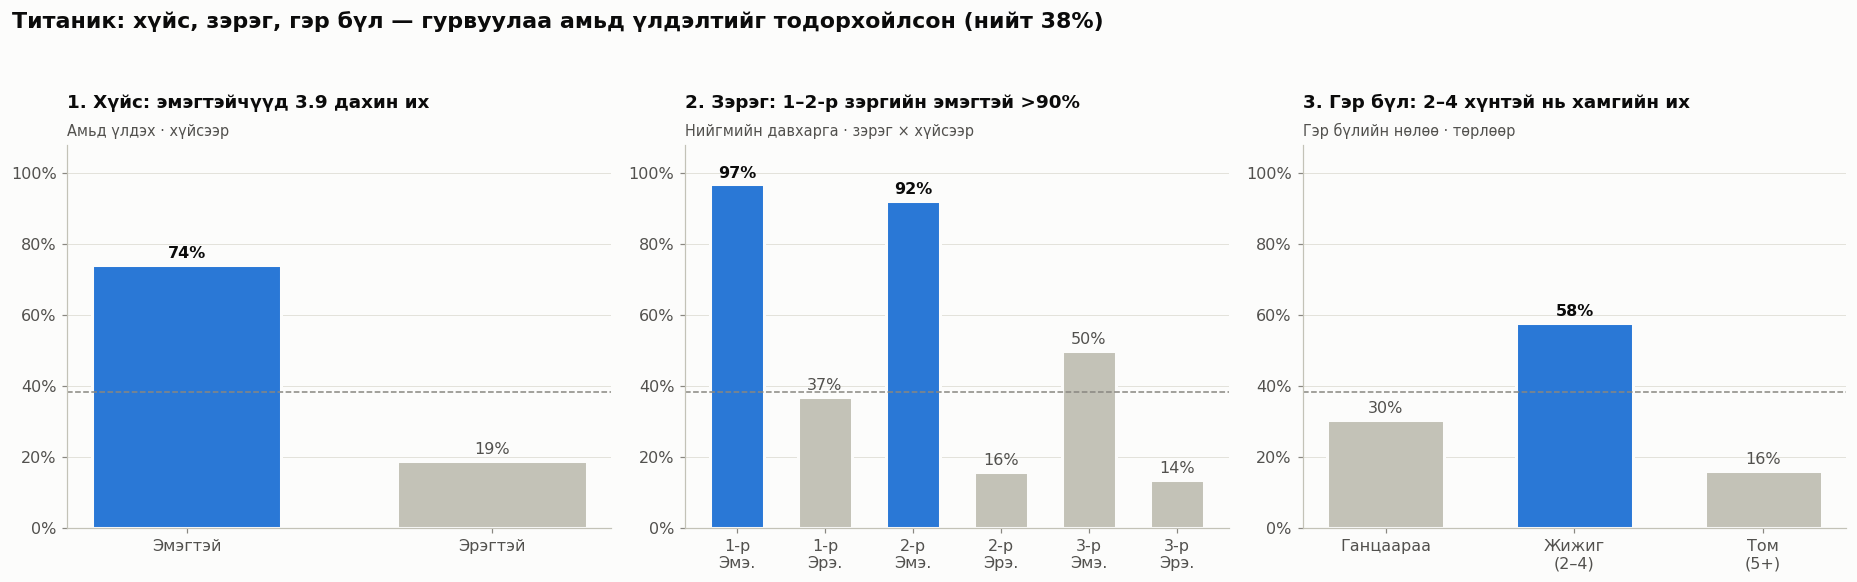

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

def panel(ax, labels, values, hi, title, sub):
    cols = [C['blue'] if i in hi else C['gray'] for i in range(len(values))]
    bars = ax.bar(labels, values, color=cols, width=0.62, edgecolor=C['surface'], linewidth=2)
    for b, v, i in zip(bars, values, range(len(values))):
        ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.0%}', ha='center',
                fontweight='bold' if i in hi else 'normal', color=C['ink'] if i in hi else C['ink2'])
    ax.axhline(OVERALL, ls='--', lw=1, color=C['muted'])
    ax.set_ylim(0, 1.08); ax.yaxis.set_major_formatter(PCT)
    ax.set_title(title, fontsize=12); subtitle(ax, sub)

s = df.groupby('Хүйс')['Survived'].mean()
panel(axes[0], ['Эмэгтэй', 'Эрэгтэй'], s.values, [0], '1. Хүйс: эмэгтэйчүүд 3.9 дахин их', 'Амьд үлдэх · хүйсээр')
pc = df.groupby(['Зэрэг', 'Хүйс'])['Survived'].mean()
panel(axes[1], [f'{a}-р\n{b[:3]}.' for a, b in pc.index], pc.values, [0, 2],
      '2. Зэрэг: 1–2-р зэргийн эмэгтэй >90%', 'Нийгмийн давхарга · зэрэг × хүйсээр')
ft = df.groupby('Гэр_бүлийн_төрөл', observed=True)['Survived'].mean()
panel(axes[2], ['Ганцаараа', 'Жижиг\n(2–4)', 'Том\n(5+)'], ft.values, [1],
      '3. Гэр бүл: 2–4 хүнтэй нь хамгийн их', 'Гэр бүлийн нөлөө · төрлөөр')
fig.suptitle(f'Титаник: хүйс, зэрэг, гэр бүл — гурвуулаа амьд үлдэлтийг тодорхойлсон (нийт {OVERALL:.0%})',
             x=0.01, ha='left', fontsize=14.5, fontweight='bold', color=C['ink'], y=1.05)
plt.tight_layout(); plt.show()

In [19]:
r = lambda q: df.query(q)['Survived'].mean()
findings = [
    ('З1 Амьд үлдэх', f"Эмэгтэй {r('Sex==\"female\"'):.0%} vs эрэгтэй {r('Sex==\"male\"'):.0%}. "
                      f"Эрэгтэйчүүдээс зөвхөн 0–12 настай хөвгүүд ({r('Sex==\"male\" and Age<=12'):.0%}) өндөр — «эмэгтэй, хүүхэд түрүүлж» биелсэн."),
    ('З2 Нийгмийн давхарга', f"1-р зэрэг {r('Pclass==1'):.0%} → 3-р зэрэг {r('Pclass==3'):.0%}. "
                             f"1-р зэргийн эмэгтэй {r('Pclass==1 and Sex==\"female\"'):.0%}, 3-р зэргийн эрэгтэй {r('Pclass==3 and Sex==\"male\"'):.0%} — 7 дахин зөрүү."),
    ('З2 (харилцан үйлчлэл)', f"3-р зэргийн эмэгтэй ({r('Pclass==3 and Sex==\"female\"'):.0%}) > 1-р зэргийн эрэгтэй ({r('Pclass==1 and Sex==\"male\"'):.0%}) — хүйсний нөлөө зэргээс хүчтэй."),
    ('З3 Гэр бүлийн нөлөө', f"Ганцаараа {r('Гэр_бүл==1'):.0%}, жижиг гэр бүл (2–4) {r('2<=Гэр_бүл<=4'):.0%}, том гэр бүл (5+) {r('Гэр_бүл>=5'):.0%} — урвуу U хэлбэр."),
]
display(pd.DataFrame(findings, columns=['Зорилго', 'Гол олдвор']).style.hide(axis='index')
        .set_properties(**{'text-align': 'left', 'font-size': '12.5px'}))

Зорилго,Гол олдвор
З1 Амьд үлдэх,"Эмэгтэй 74% vs эрэгтэй 19%. Эрэгтэйчүүдээс зөвхөн 0–12 настай хөвгүүд (57%) өндөр — «эмэгтэй, хүүхэд түрүүлж» биелсэн."
З2 Нийгмийн давхарга,"1-р зэрэг 63% → 3-р зэрэг 24%. 1-р зэргийн эмэгтэй 97%, 3-р зэргийн эрэгтэй 14% — 7 дахин зөрүү."
З2 (харилцан үйлчлэл),3-р зэргийн эмэгтэй (50%) > 1-р зэргийн эрэгтэй (37%) — хүйсний нөлөө зэргээс хүчтэй.
З3 Гэр бүлийн нөлөө,"Ганцаараа 30%, жижиг гэр бүл (2–4) 58%, том гэр бүл (5+) 16% — урвуу U хэлбэр."


### Visual mapping-ын хураангуй
1. **Юуг холбох вэ?** — Зорилгоос эхэлж (3 асуулт), талбар бүрийн **төрлийг** (нэрлэсэн / эрэмбэтэй / тоон) тодорхойлсон. Буруу хэмжүүр (тоо ↔ хувь) сонгох нь ямар ч гоё графикийг худал болгодог (5.1-А).
2. **Хэрхэн холбох вэ?** — Гол тоон хэмжүүрийг хамгийн нарийн суваг болох **байрлал/уртад**, ангиллыг **өнгөний төрөлд**, итгэлцүүрийг **хэмжээнд**, эрэмбийг **цайвар→бараанд**, дунджаас хазайлтыг **diverging өнгөнд** оноосон.
3. **Хүний хараа** — Нэг графикт нэг pop-out, ≤4 өнгө, шууд шошго, тогтвортой өнгө (хүйс бүх графикт ижил), CVD-д шалгагдсан палитр, гарчиг = олдвор.

*Эх сурвалж: Bertin (1967) Semiology of Graphics; Cleveland & McGill (1984); Healey & Enns (2012) Attention and Visual Memory in Visualization; Munzner (2014) Visualization Analysis & Design; Machado et al. (2009) CVD simulation.*

---
# 7. Нуугдмал олдворууд — ихэнх хүн олж хараагүй зүйлс

«Эмэгтэйчүүд, 1-р зэргийнхэн амьд үлдсэн» гэдгийг бүгд мэднэ. Энэ хэсэгт **нэг хувьсагчаар харахад далд үлддэг** 5 хэв маягийг гаргана. Олдвор бүрийг ингэж харуулна:

**Нээлт → Яаж олсон (ямар шинэ талбар/арга) → Visual mapping-ын шийдэл → Яагаад чухал**

| # | Олдвор | Нуугдаж байсан шалтгаан |
|---|---|---|
| Н1 | Хувь заяа **бүлгээрээ** шийдэгдсэн | Өгөгдөл хүн нэг бүрээр — бүлгийн түвшин харагддаггүй |
| Н2 | «Эмэгтэй, хүүхэд түрүүлж» дүрэм 3-р зэрэгт **нурсан** | Дундаж нь (74%) дэд бүлгийн уналтыг нууна |
| Н3 | **Дутуу өгөгдөл өөрөө дохио** | Дутуу утгыг ихэвчлэн устгадаг/нөхдөг |
| Н4 | Cherbourg боомтын «аз» — **бүтцийн нөлөө** | Холбоо ≠ шалтгаан (confounding) |
| Н5 | `Fare` бол хүний биш, **тасалбарын** үнэ | Талбарын утгыг буруу ойлгох хавх |

In [20]:
# Шинэ талбарууд
df['Цол'] = df['Name'].str.extract(r',\s*([^\.]+)\.')[0]           # Mr, Mrs, Miss, Master…
df['Тасалбар_бүлэг'] = df.groupby('Ticket')['Ticket'].transform('size') # нэг тасалбараар явсан хүний тоо
df['Хүнд_ногдох_үнэ'] = df['Fare'] / df['Тасалбар_бүлэг']
print('Нэг тасалбараар 2+ хүн явсан бүлэг:', (df.groupby('Ticket').size() >= 2).sum())
print('Гэр бүлийн хэмжээ ≠ тасалбарын бүлэг:', f"{(df['Тасалбар_бүлэг'] != df['Гэр_бүл']).mean():.0%}",
      '→ найз, үйлчлэгч гэх мэт гэр бүлийн бус хамтрагчид байсан')

Нэг тасалбараар 2+ хүн явсан бүлэг: 134
Гэр бүлийн хэмжээ ≠ тасалбарын бүлэг: 32% → найз, үйлчлэгч гэх мэт гэр бүлийн бус хамтрагчид байсан


## Н1. Хувь заяа бүлгээрээ шийдэгдсэн — «хэнтэй хамт явсан бэ» нь «хэн бэ»-ээс хүчтэй

**Яаж олсон:** `Ticket`-ийг танигч гэж хаядаг. Гэвч нэг тасалбартай хүмүүс = хамт аялсан бүлэг (гэр бүл, найз, үйлчлэгч). Бүлэг бүрт «**бүгд амьд / бүгд нас барсан**» байх магадлалыг санамсаргүй хуваарилалттай (**permutation test**, 2000 удаа) харьцуулав.

**Mapping:** зүүн — санамсаргүй тархалт = саарал гистограм, бодит утга = цэнхэр босоо шугам (байрлалаар pop-out). Баруун — хамтрагчдын хувь заяа → X-байрлал (эрэмбэ), амьд үлдэлт → Y, хүйс → өнгө.

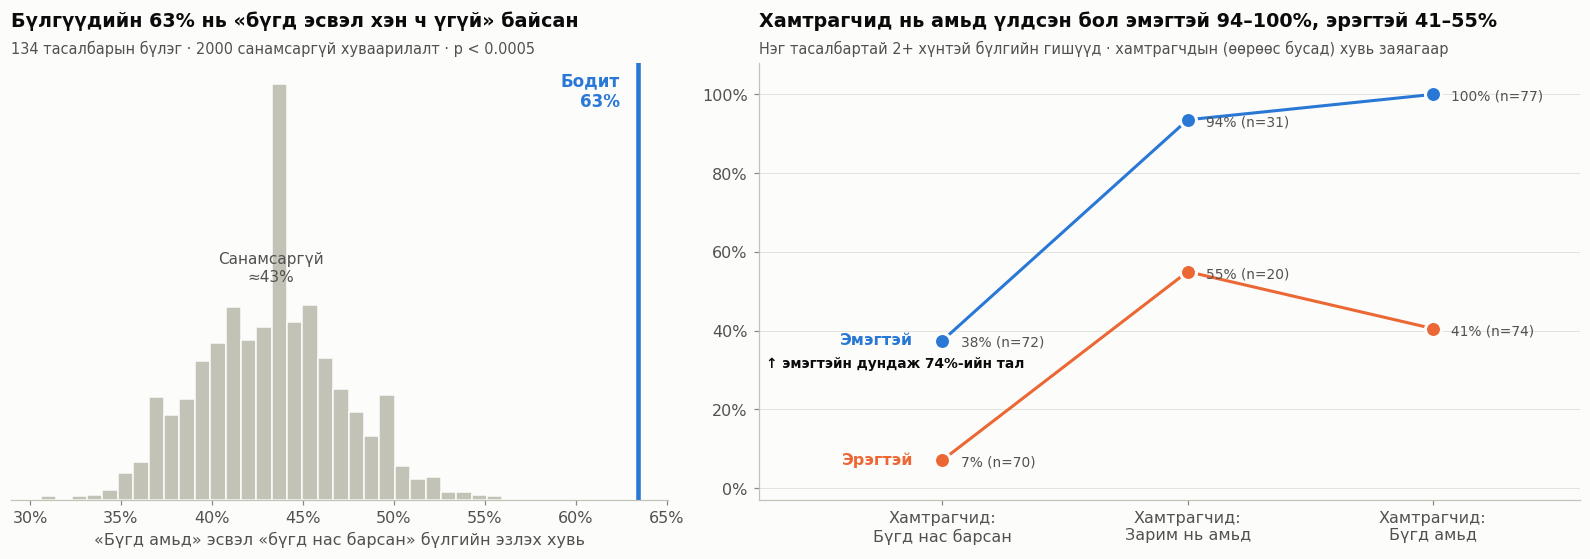

In [21]:
grp = df[df['Тасалбар_бүлэг'] >= 2].copy()
codes, _ = pd.factorize(grp['Ticket']); sizes = np.bincount(codes)
def homog(surv):
    s = np.bincount(codes, weights=surv); return np.mean((s == 0) | (s == sizes))
observed = homog(grp['Survived'].values)
rng = np.random.default_rng(42); allv = df['Survived'].values; idx = grp.index.values
sims = np.array([homog(rng.permutation(allv)[:len(grp)]) for _ in range(2000)])
p_val = (sims >= observed).mean()

grp['others'] = (grp.groupby('Ticket')['Survived'].transform('sum') - grp['Survived']) / (grp['Тасалбар_бүлэг'] - 1)
OTH = ['Бүгд нас барсан', 'Зарим нь амьд', 'Бүгд амьд']
grp['Хамтрагчид'] = pd.cut(grp['others'], [-0.01, 0, 0.999, 1], labels=OTH)
h = grp.groupby(['Хүйс', 'Хамтрагчид'], observed=True)['Survived'].agg(['mean', 'size']).reset_index()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1, 1.25]})
a1.hist(sims, bins=30, color=C['gray'], edgecolor=C['surface'], linewidth=1)
a1.axvline(observed, color=C['blue'], lw=3)
a1.text(observed - 0.01, a1.get_ylim()[1]*0.9, f'Бодит\n{observed:.0%}', color=C['blue'], fontweight='bold', ha='right', fontsize=11)
a1.text(sims.mean(), a1.get_ylim()[1]*0.5, f'Санамсаргүй\n≈{sims.mean():.0%}', color=C['ink2'], ha='center', fontsize=10)
a1.xaxis.set_major_formatter(PCT); a1.set_yticks([]); a1.spines['left'].set_visible(False); a1.grid(False)
a1.set_xlabel('«Бүгд амьд» эсвэл «бүгд нас барсан» бүлгийн эзлэх хувь')
a1.set_title('Бүлгүүдийн 63% нь «бүгд эсвэл хэн ч үгүй» байсан')
subtitle(a1, f'{sizes.size} тасалбарын бүлэг · 2000 санамсаргүй хуваарилалт · p < {max(p_val, 1/2000):.4f}')

xp = {k: i for i, k in enumerate(OTH)}
for sex, sub in h.groupby('Хүйс'):
    xx = sub['Хамтрагчид'].map(xp).astype(int)
    a2.plot(xx, sub['mean'], color=SEX_COLOR[sex], lw=2)
    a2.scatter(xx, sub['mean'], s=110, color=SEX_COLOR[sex], edgecolor=C['surface'], linewidth=2, zorder=3)
    for _, r in sub.iterrows():
        a2.annotate(f"{r['mean']:.0%} (n={r['size']})", (xp[r['Хамтрагчид']], r['mean']), textcoords='offset points',
                    xytext=(12, -4), fontsize=9, color=C['ink2'])
    a2.text(-0.12, sub['mean'].iloc[0], sex, color=SEX_COLOR[sex], fontweight='bold', ha='right', va='center')
F_ALL = df.loc[df['Sex'] == 'female', 'Survived'].mean()
fem_none = h.query('Хүйс=="Эмэгтэй" and Хамтрагчид=="Бүгд нас барсан"')['mean'].iloc[0]
a2.text(-0.72, fem_none - 0.07, f'↑ эмэгтэйн дундаж {F_ALL:.0%}-ийн тал', fontsize=9, color=C['ink'], fontweight='bold')
a2.set_xticks(range(3), [f'Хамтрагчид:\n{k}' for k in OTH]); a2.set_xlim(-0.75, 2.6)
a2.set_ylim(-0.03, 1.08); a2.yaxis.set_major_formatter(PCT)
a2.set_title('Хамтрагчид нь амьд үлдсэн бол эмэгтэй 94–100%, эрэгтэй 41–55%')
subtitle(a2, 'Нэг тасалбартай 2+ хүнтэй бүлгийн гишүүд · хамтрагчдын (өөрөөс бусад) хувь заяагаар')
plt.tight_layout(); plt.show()

> **Яагаад чухал:** Хүн нэг бүрийн шинж (хүйс, зэрэг) нь түүх **хагас** нь. Бүлэг хамтдаа шийдвэр гаргаж (хамт үлдэх, хамт явах), хамтдаа амьд үлдсэн эсвэл хамтдаа нас барсан. **Аналитикчдад сургамж:** өгөгдөл хувь хүнийх байсан ч шийдвэр **өрх/бүлгийн** түвшинд гардаг бол бүлгийн танигчийг (энд `Ticket`, захиргааны өгөгдөлд өрхийн дугаар) хаяж болохгүй.

## Н2. «Эмэгтэй, хүүхэд түрүүлж» дүрэм хаана нурсан бэ?

**Яаж олсон:** `Name`-ээс **цол** (`Master` = хөвгүүн) гаргаж, насны дутуу утгатай ч хөвгүүдийг таних боломжтой болгосон. Дараа нь «дүрэмд хамгаалагдах ёстой» бүлгүүдийг зэрэг, гэр бүлийн хэмжээгээр задлав.

**Mapping:** бүлэг → Y-байрлал · амьд үлдэлт → баганын урт · **дүрэм нурсан бүлэг = улаан (онцлол)**, дүрэм биелсэн = цэнхэр · эмэгтэй/эрэгтэйн дундаж → 2 лавлах шугам (харьцуулах цэг).

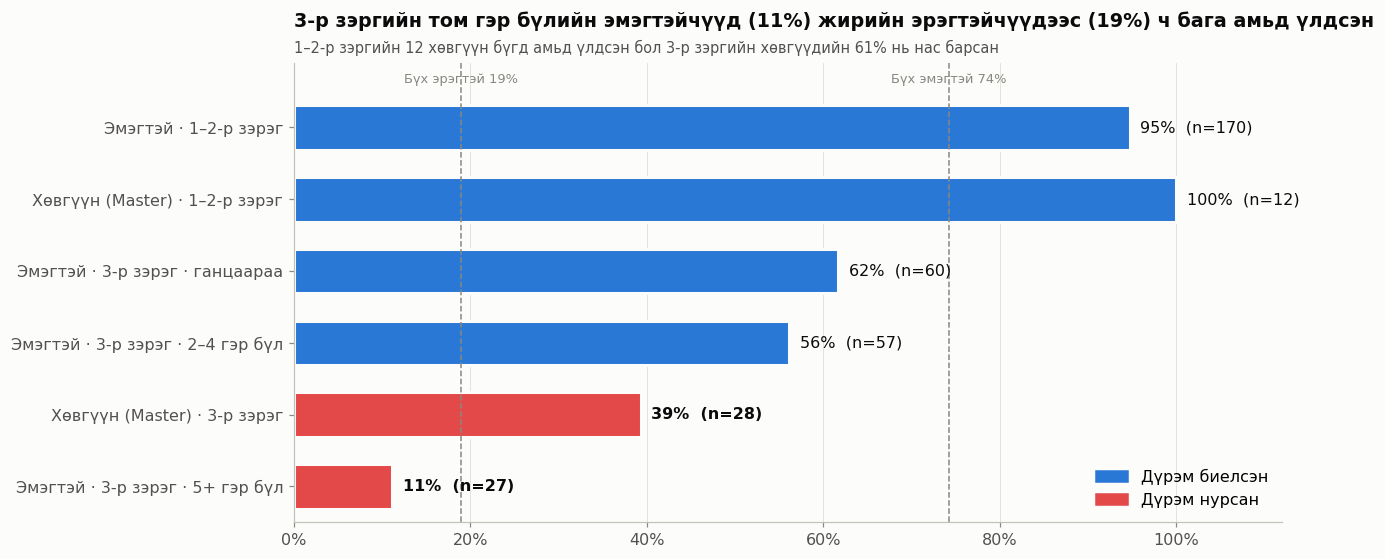

In [22]:
def rr(mask): s = df.loc[mask, 'Survived']; return s.mean(), len(s)
male = df['Sex'] == 'male'; fem = ~male; boy = df['Цол'] == 'Master'
p3 = df['Pclass'] == 3; p12 = ~p3; fam = df['Гэр_бүл']
rows = [
    ('Эмэгтэй · 1–2-р зэрэг',             *rr(fem & p12)),
    ('Хөвгүүн (Master) · 1–2-р зэрэг',     *rr(boy & p12)),
    ('Эмэгтэй · 3-р зэрэг · ганцаараа',    *rr(fem & p3 & (fam == 1))),
    ('Эмэгтэй · 3-р зэрэг · 2–4 гэр бүл',  *rr(fem & p3 & fam.between(2, 4))),
    ('Хөвгүүн (Master) · 3-р зэрэг',       *rr(boy & p3)),
    ('Эмэгтэй · 3-р зэрэг · 5+ гэр бүл',   *rr(fem & p3 & (fam >= 5))),
]
r2 = pd.DataFrame(rows, columns=['Бүлэг', 'rate', 'n'])
F_AVG, M_AVG = df.loc[fem, 'Survived'].mean(), df.loc[male, 'Survived'].mean()

fig, ax = plt.subplots(figsize=(12, 5.2))
cols = [C['red'] if v < 0.45 else C['blue'] for v in r2['rate']]
bars = ax.barh(r2['Бүлэг'], r2['rate'], color=cols, height=0.62, edgecolor=C['surface'], linewidth=2)
for b, v, n in zip(bars, r2['rate'], r2['n']):
    ax.text(v + 0.012, b.get_y() + b.get_height()/2, f'{v:.0%}  (n={n})', va='center',
            color=C['ink'], fontweight='bold' if v < 0.45 else 'normal')
for val, lab in [(F_AVG, f'Бүх эмэгтэй {F_AVG:.0%}'), (M_AVG, f'Бүх эрэгтэй {M_AVG:.0%}')]:
    ax.axvline(val, ls='--', lw=1, color=C['muted']); ax.text(val, -0.62, lab, color=C['muted'], fontsize=8.5, ha='center')
ax.invert_yaxis(); ax.set_xlim(0, 1.12); ax.set_ylim(5.5, -0.9); ax.xaxis.set_major_formatter(PCT)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=C['blue'], label='Дүрэм биелсэн'), Patch(color=C['red'], label='Дүрэм нурсан')],
          loc='lower right')
ax.set_title('3-р зэргийн том гэр бүлийн эмэгтэйчүүд (11%) жирийн эрэгтэйчүүдээс (19%) ч бага амьд үлдсэн')
subtitle(ax, '1–2-р зэргийн 12 хөвгүүн бүгд амьд үлдсэн бол 3-р зэргийн хөвгүүдийн 61% нь нас барсан')
plt.tight_layout(); plt.show()

> **Яагаад чухал:** «Эмэгтэйчүүд 74% амьд үлдсэн» гэдэг дундаж нь хамгийн эмзэг бүлгийн (3-р зэрэг, олон хүүхэдтэй ээжүүд) **уналтыг нууж** байна. Олон хүүхэдтэй ээж хүүхдүүдээ цуглуулж, доод давхраас дээш гарах хугацаа олдоогүй байх магадлалтай. **Аналитикчдад сургамж:** дунджийг дэд бүлгээр (сегментээр) задлахгүйгээр «бодлого үр дүнтэй» гэж дүгнэх нь хамгийн эмзэг бүлгийг алдах эрсдэлтэй.

## Н3. Дутуу өгөгдөл өөрөө дохио — survivorship bias

**Яаж олсон:** `Cabin` (77% дутуу), `Age` (20% дутуу)-г ихэвчлэн устгадаг эсвэл дундажаар нөхдөг. Харин «**дутуу эсэх**»-ийг шинэ хувьсагч болгож, зэрэг тус бүрт амьд үлдэлттэй харьцуулав. Зэргээр хянасан учир «баян хүмүүс кабинтай» гэсэн тайлбар үгүйсгэгдэнэ.

**Mapping:** slope chart — «бүртгэгдсэн» ба «дутуу» = 2 X-байрлал, зэрэг бүр = нэг шугам (дараалсан цэнхэр), налуу = дутуу байдлын нөлөө. Налуу их байх тусам preattentive-аар шууд анзаарагдана.

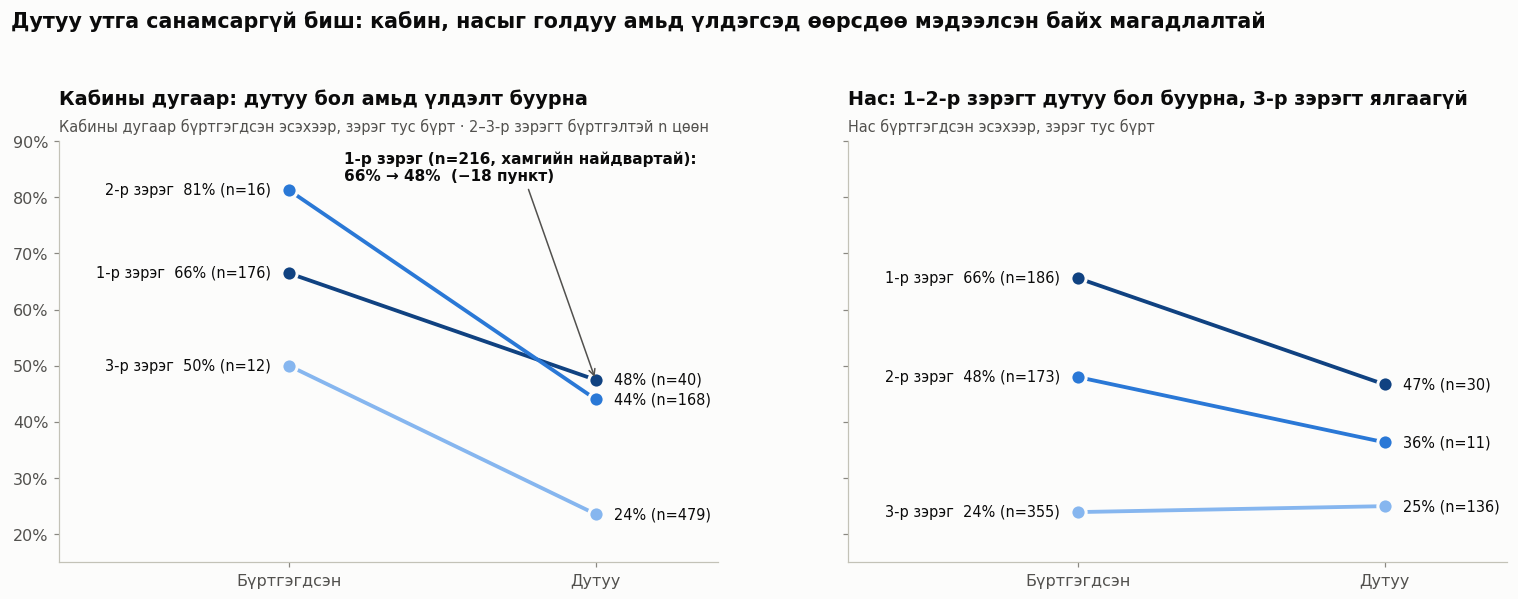

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, col, ttl in [(axes[0], 'Cabin', 'Кабины дугаар'), (axes[1], 'Age', 'Нас')]:
    t = df.assign(miss=df[col].isna()).groupby(['Pclass', 'miss'])['Survived'].agg(['mean', 'size']).unstack()
    for cls in [1, 2, 3]:
        known, miss = t.loc[cls, ('mean', False)], t.loc[cls, ('mean', True)]
        nk, nm = t.loc[cls, ('size', False)], t.loc[cls, ('size', True)]
        ax.plot([0, 1], [known, miss], color=CLASS_COLOR[cls], lw=2.5, marker='o', ms=10,
                markeredgecolor=C['surface'], markeredgewidth=2)
        ax.text(-0.06, known, f'{cls}-р зэрэг  {known:.0%} (n={nk})', ha='right', va='center', color=C['ink'], fontsize=9.5)
        ax.text(1.06, miss, f'{miss:.0%} (n={nm})', ha='left', va='center', color=C['ink'], fontsize=9.5)
    ax.set_xticks([0, 1], ['Бүртгэгдсэн', 'Дутуу']); ax.set_xlim(-0.75, 1.4)
    ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0.15, 0.9); ax.grid(axis='y')
    ax.set_title(f'{ttl}: дутуу бол амьд үлдэлт буурна' if col == 'Cabin' else 'Нас: 1–2-р зэрэгт дутуу бол буурна, 3-р зэрэгт ялгаагүй')
    subtitle(ax, f'{ttl} бүртгэгдсэн эсэхээр, зэрэг тус бүрт' + (' · 2–3-р зэрэгт бүртгэлтэй n цөөн' if col == 'Cabin' else ''))
axes[0].annotate('1-р зэрэг (n=216, хамгийн найдвартай):\n66% → 48%  (−18 пункт)', xy=(1, 0.475), xytext=(0.18, 0.83), fontsize=10, fontweight='bold',
                 color=C['ink'], arrowprops=dict(arrowstyle='->', color=C['ink2']))
fig.suptitle('Дутуу утга санамсаргүй биш: кабин, насыг голдуу амьд үлдэгсэд өөрсдөө мэдээлсэн байх магадлалтай',
             x=0.01, ha='left', fontsize=13.5, fontweight='bold', color=C['ink'], y=1.04)
plt.tight_layout(); plt.show()

> **Яагаад чухал:** Хамгийн үнэмшилтэй тайлбар: амьд үлдсэн хүн өөрийн кабин, насыг хэлж өгсөн; нас барсан хүний мэдээллийг хэлэх хүн байгаагүй. Зэрэг тус бүрт ижил чиглэл ажиглагдсан нь «зөвхөн баян хүмүүс кабинтай» гэсэн тайлбарыг үгүйсгэнэ. Тиймээс **дутуу байх нь өөрөө үхлийн дохио** — загварт `Cabin` устгавал мэдээлэл алдана, дундажаар нөхвөл гажуудал үүснэ. **Аналитикчдад сургамж:** захиргааны өгөгдөлд «бүртгэлгүй/дутуу» бүлэг ихэвчлэн хамгийн эмзэг бүлэг байдаг — дутуу байдлыг тусдаа ангилал болгон шинжлэх хэрэгтэй.

## Н4. Cherbourg боомтын «аз» — үнэндээ хэн суусных

**Яаж олсон:** Cherbourg (C)-оос суусан хүмүүс 55%, Southampton (S)-аас 34% амьд үлдсэн — «боомт нөлөөлсөн» мэт. **Шууд стандартчлал**: боомт бүрийн зорчигчдод нийт өгөгдлийн *зэрэг × хүйсний* амьд үлдэлтийг оноож «хүлээгдэх» утгыг тооцоод бодит утгатай харьцуулав.

**Mapping:** dumbbell — хүлээгдэх (хоосон дугуй) ба бодит (дүүрэн дугуй) = нэг тэнхлэг дээрх 2 байрлал; тэдгээрийн зай = боомтын «цэвэр» нөлөө.

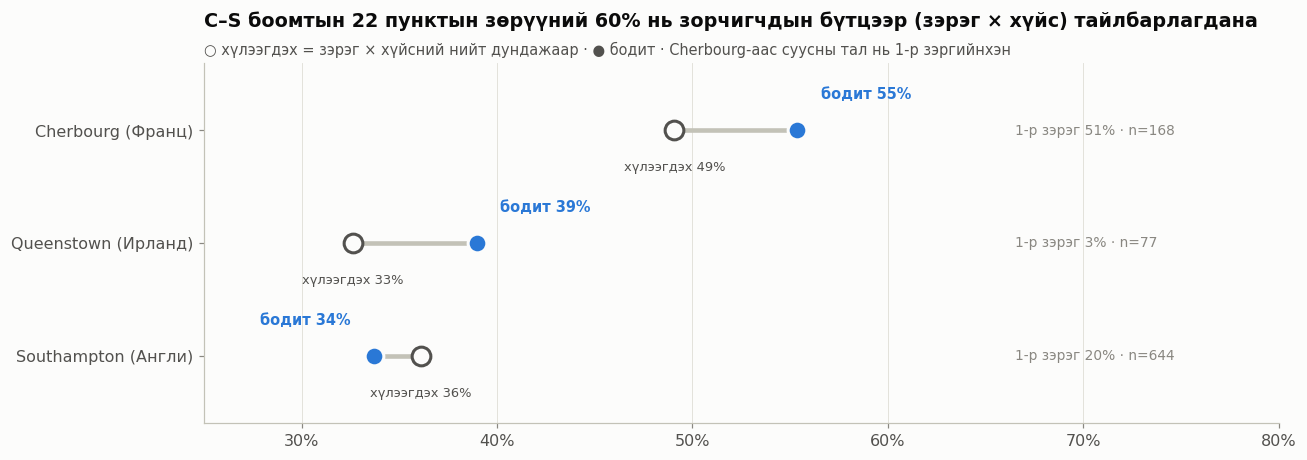

In [24]:
e = df.dropna(subset=['Embarked']).copy()
base = e.groupby(['Pclass', 'Sex'])['Survived'].mean()
e['Хүлээгдэх'] = [base[(p, s)] for p, s in zip(e['Pclass'], e['Sex'])]
pt = e.groupby('Embarked').agg(Бодит=('Survived', 'mean'), Хүлээгдэх=('Хүлээгдэх', 'mean'), n=('Survived', 'size'),
                               Зэрэг1=('Pclass', lambda s: (s == 1).mean())).loc[['C', 'Q', 'S']]
gap_raw = pt.loc['C', 'Бодит'] - pt.loc['S', 'Бодит']; gap_exp = pt.loc['C', 'Хүлээгдэх'] - pt.loc['S', 'Хүлээгдэх']
share = gap_exp / gap_raw
names = {'C': 'Cherbourg (Франц)', 'Q': 'Queenstown (Ирланд)', 'S': 'Southampton (Англи)'}

fig, ax = plt.subplots(figsize=(12, 4.3))
for i, (port, r) in enumerate(pt.iterrows()):
    ax.plot([r['Хүлээгдэх'], r['Бодит']], [i, i], color=C['gray'], lw=3, zorder=1)
    ax.scatter(r['Хүлээгдэх'], i, s=150, facecolor=C['surface'], edgecolor=C['ink2'], linewidth=2, zorder=3)
    ax.scatter(r['Бодит'], i, s=150, color=C['blue'], edgecolor=C['surface'], linewidth=2, zorder=3)
    ax.text(r['Бодит'] + (0.012 if r['Бодит'] > r['Хүлээгдэх'] else -0.012), i - 0.28, f"бодит {r['Бодит']:.0%}",
            ha='left' if r['Бодит'] > r['Хүлээгдэх'] else 'right', color=C['blue'], fontweight='bold', fontsize=9.5)
    ax.text(r['Хүлээгдэх'], i + 0.36, f"хүлээгдэх {r['Хүлээгдэх']:.0%}", ha='center', color=C['ink2'], fontsize=8.5)
    ax.text(0.665, i, f"1-р зэрэг {r['Зэрэг1']:.0%} · n={int(r['n'])}", va='center', color=C['muted'], fontsize=9)
ax.set_yticks(range(3), [names[p] for p in pt.index]); ax.invert_yaxis(); ax.set_ylim(2.6, -0.6)
ax.set_xlim(0.25, 0.8); ax.xaxis.set_major_formatter(PCT); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title(f'C–S боомтын {gap_raw*100:.0f} пунктын зөрүүний {share:.0%} нь зорчигчдын бүтцээр (зэрэг × хүйс) тайлбарлагдана')
subtitle(ax, '○ хүлээгдэх = зэрэг × хүйсний нийт дундажаар · ● бодит · Cherbourg-аас суусны тал нь 1-р зэргийнхэн')
plt.tight_layout(); plt.show()

> **Яагаад чухал:** Нэг хувьсагчийн график «боомт нөлөөлсөн» гэсэн **хуурамч шалтгаан** үүсгэдэг. Стандартчилсны дараа үлдэх ~9 пунктын зөрүүг өөр нуугдмал хүчин зүйл (жишээ нь Cherbourg-ийн 1-р зэргийнхэн дээд давхарт байрласан) тайлбарлаж магадгүй. **Аналитикчдад сургамж:** аймаг/дүүргийн харьцуулалтад насны бүтэц, өрхийн бүтцээр стандартчлахгүй бол «бүс нутгийн ялгаа» нь ихэвчлэн «хүн амын бүтцийн ялгаа» байдаг.

## Н5. `Fare` хавх — хүний биш, тасалбарын үнэ

**Яаж олсон:** Нэг тасалбартай хүмүүсийн `Fare` яг ижил байдаг → энэ нь **нийт тасалбарын үнэ**. Хүнд ногдох үнийг (`Fare / Тасалбар_бүлэг`) тооцвол зэргүүдийн ялгаа өөрөөр харагдана. Мөн `Fare = 0` бүлэг онцгой.

**Mapping:** зүүн — dumbbell (тасалбарын үнэ → хүнд ногдох), лог масштаб; баруун — **unit chart** (1 дөрвөлжин = 1 хүн), амьд = цэнхэр, нас барсан = саарал — цөөн тоог хувиар биш хүнээр харуулах нь илүү ойлгомжтой.

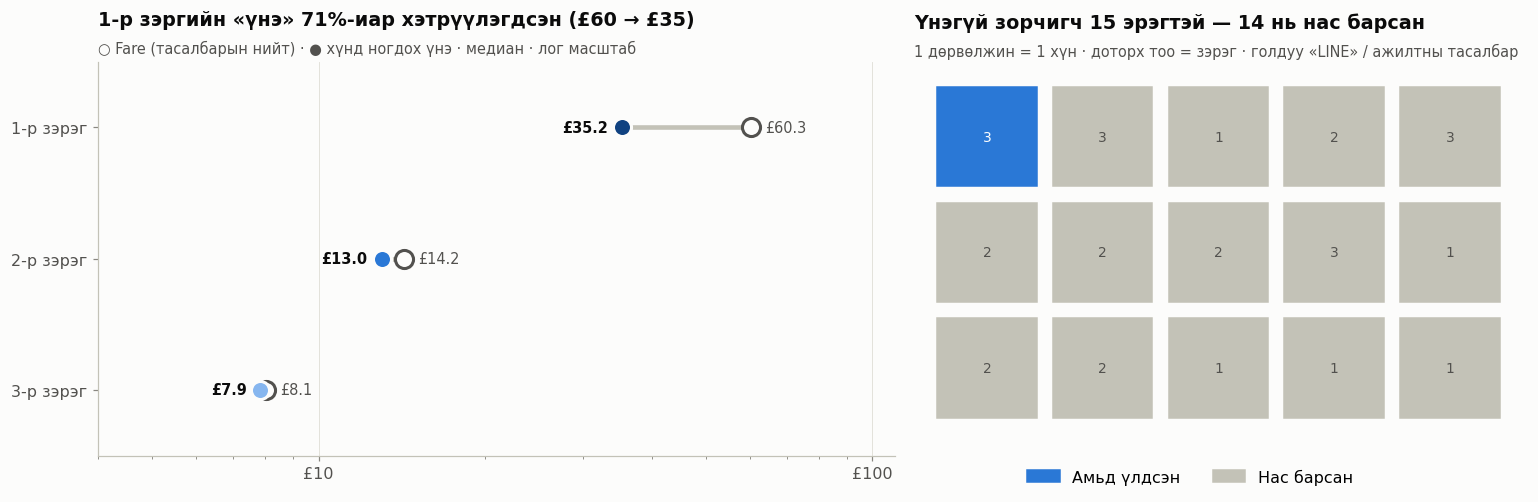

In [25]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.3, 1]})
fm = df.groupby('Pclass')[['Fare', 'Хүнд_ногдох_үнэ']].median()
for i, (cls, r) in enumerate(fm.iterrows()):
    a1.plot([r['Хүнд_ногдох_үнэ'], r['Fare']], [i, i], color=C['gray'], lw=3)
    a1.scatter(r['Fare'], i, s=140, facecolor=C['surface'], edgecolor=C['ink2'], linewidth=2, zorder=3)
    a1.scatter(r['Хүнд_ногдох_үнэ'], i, s=140, color=CLASS_COLOR[cls], edgecolor=C['surface'], linewidth=2, zorder=3)
    a1.text(r['Fare'] * 1.06, i, f"£{r['Fare']:.1f}", va='center', color=C['ink2'], fontsize=9.5)
    a1.text(r['Хүнд_ногдох_үнэ'] / 1.06, i, f"£{r['Хүнд_ногдох_үнэ']:.1f}", va='center', ha='right', color=C['ink'], fontweight='bold', fontsize=9.5)
a1.set_xscale('log'); a1.set_xlim(4, 110); a1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'£{v:g}'))
a1.set_yticks(range(3), ['1-р зэрэг', '2-р зэрэг', '3-р зэрэг']); a1.invert_yaxis(); a1.set_ylim(2.5, -0.5)
a1.grid(axis='x'); a1.grid(axis='y', visible=False)
a1.set_title(f"1-р зэргийн «үнэ» {fm.loc[1,'Fare']/fm.loc[1,'Хүнд_ногдох_үнэ']-1:.0%}-иар хэтрүүлэгдсэн (£{fm.loc[1,'Fare']:.0f} → £{fm.loc[1,'Хүнд_ногдох_үнэ']:.0f})")
subtitle(a1, '○ Fare (тасалбарын нийт) · ● хүнд ногдох үнэ · медиан · лог масштаб')

z = df[df['Fare'] == 0].sort_values('Survived', ascending=False)
for k, (_, r) in enumerate(z.iterrows()):
    xx, yy = k % 5, k // 5
    a2.add_patch(plt.Rectangle((xx, -yy), 0.86, 0.86, color=C['blue'] if r['Survived'] else C['gray']))
    a2.text(xx + 0.43, -yy + 0.43, f"{r['Pclass']}", ha='center', va='center', fontsize=9,
            color='white' if r['Survived'] else C['ink2'])
a2.set_xlim(-0.2, 5.1); a2.set_ylim(-2.3, 1.05); a2.set_aspect('equal'); a2.axis('off')
a2.set_title(f"Үнэгүй зорчигч {len(z)} эрэгтэй — {len(z) - z['Survived'].sum()} нь нас барсан")
subtitle(a2, '1 дөрвөлжин = 1 хүн · доторх тоо = зэрэг · голдуу «LINE» / ажилтны тасалбар')
a2.legend(handles=[Patch(color=C['blue'], label='Амьд үлдсэн'), Patch(color=C['gray'], label='Нас барсан')], loc='lower center', ncol=2, bbox_to_anchor=(0.45, -0.12))
plt.tight_layout(); plt.show()

> **Яагаад чухал:** `Fare`-ийг шууд «баялгийн хэмжүүр» гэж хэрэглэвэл том гэр бүлтэй хүмүүс «баян» мэт харагдаж, гэр бүлийн нөлөө ба баялгийн нөлөө холилдоно. Үнэгүй 15 зорчигч бол ажилтан/хүргэлтийн бүлэг (American Line, Harland & Wolff) — 93% нь нас барсан нь багийнхны хувь заяатай төстэй. **Аналитикчдад сургамж:** талбарын **нэгж** (хүн үү, өрх үү, тасалбар уу) тодорхой биш бол бүх дүгнэлт гажина — тэтгэмж ч гэсэн «өрхөд» үү, «хүнд» үү гэдгийг шалгах.

## Нуугдмал олдворын нэгтгэсэн самбар

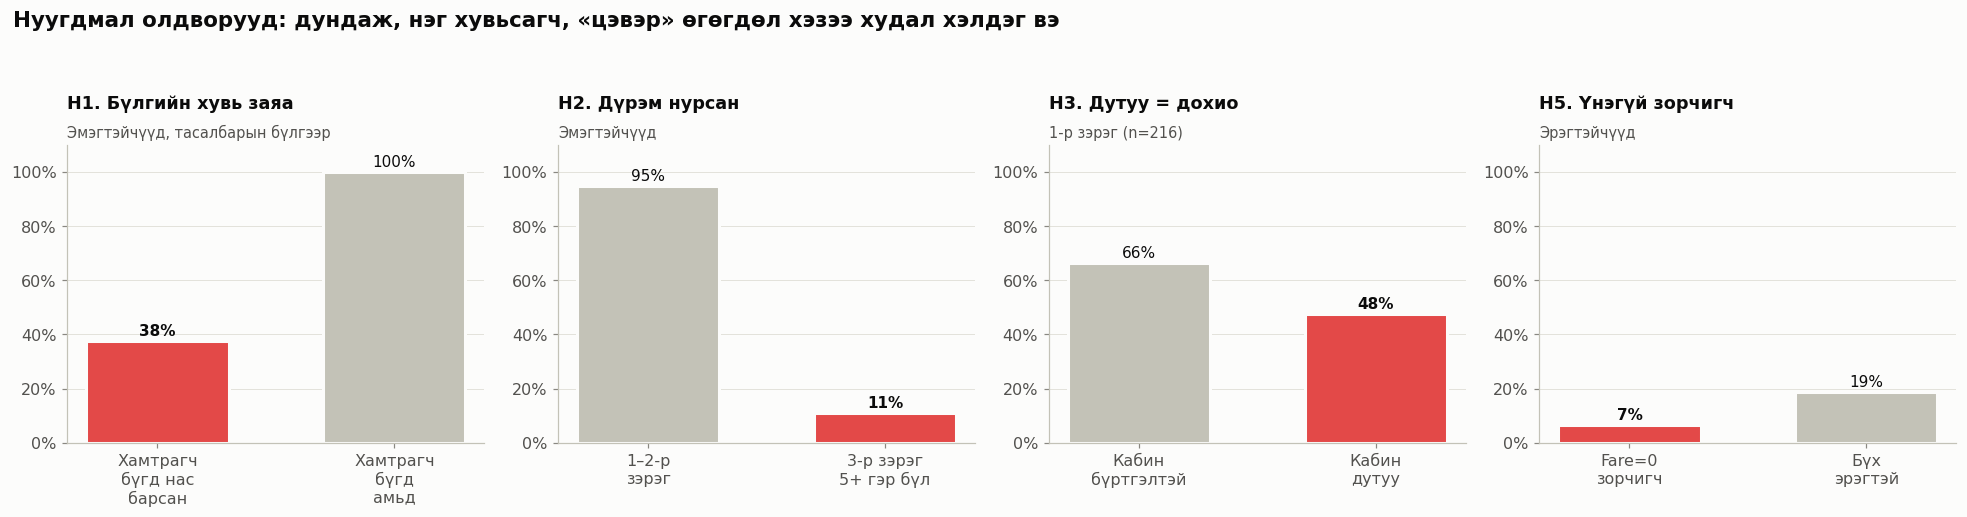

#,Олдвор,Арга,Аналитикчдад сургамж
Н1,Тасалбарын бүлгийн 63% нь «бүгд эсвэл хэн ч үгүй» (санамсаргүй 43%),"Ticket → бүлэг, permutation test",Өрх/бүлгийн түвшинд шинжлэх
Н2,"3-р зэргийн том гэр бүлийн эмэгтэй 11%, хөвгүүд 39%","Name → цол, сегмент задлал",Дунджийг сегментээр задлах
Н3,Кабин дутуу бол амьд үлдэлт бүх зэрэгт бага (1-р: 48% vs 66%),Дутуу эсэх → хувьсагч,Дутуу утга = тусдаа ангилал
Н4,C–S зөрүүний 60% нь зорчигчдын бүтэц,Шууд стандартчлал,Бүсийн харьцуулалтыг стандартчлах
Н5,1-р зэргийн медиан үнэ ~70% хэтрүүлэгдсэн; үнэгүй 15-аас 14 нас барсан,Fare / бүлгийн хэмжээ,Талбарын нэгжийг шалгах


In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
def mini(ax, labels, vals, hi, title, sub):
    cols = [C['red'] if i in hi else C['gray'] for i in range(len(vals))]
    bars = ax.bar(labels, vals, color=cols, width=0.6, edgecolor=C['surface'], linewidth=2)
    for b, v, i in zip(bars, vals, range(len(vals))):
        ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.0%}', ha='center', fontsize=10,
                fontweight='bold' if i in hi else 'normal', color=C['ink'])
    ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(PCT); ax.set_title(title, fontsize=11.5); subtitle(ax, sub)

hh = h.set_index(['Хүйс', 'Хамтрагчид'])['mean']
mini(axes[0], ['Хамтрагч\nбүгд нас\nбарсан', 'Хамтрагч\nбүгд\nамьд'], [hh[('Эмэгтэй', OTH[0])], hh[('Эмэгтэй', OTH[2])]], [0],
     'Н1. Бүлгийн хувь заяа', 'Эмэгтэйчүүд, тасалбарын бүлгээр')
mini(axes[1], ['1–2-р\nзэрэг', '3-р зэрэг\n5+ гэр бүл'], [r2['rate'][0], r2['rate'][5]], [1],
     'Н2. Дүрэм нурсан', 'Эмэгтэйчүүд')
cab = df.assign(m=df['Cabin'].isna()).query('Pclass==1').groupby('m')['Survived'].mean()
mini(axes[2], ['Кабин\nбүртгэлтэй', 'Кабин\nдутуу'], [cab[False], cab[True]], [1], 'Н3. Дутуу = дохио', '1-р зэрэг (n=216)')
mini(axes[3], ['Fare=0\nзорчигч', 'Бүх\nэрэгтэй'], [z['Survived'].mean(), M_AVG], [0], 'Н5. Үнэгүй зорчигч', 'Эрэгтэйчүүд')
fig.suptitle('Нуугдмал олдворууд: дундаж, нэг хувьсагч, «цэвэр» өгөгдөл хэзээ худал хэлдэг вэ', x=0.01, ha='left',
             fontsize=14, fontweight='bold', color=C['ink'], y=1.06)
plt.tight_layout(); plt.show()

summary = pd.DataFrame([
    ['Н1', 'Тасалбарын бүлгийн 63% нь «бүгд эсвэл хэн ч үгүй» (санамсаргүй 43%)', 'Ticket → бүлэг, permutation test', 'Өрх/бүлгийн түвшинд шинжлэх'],
    ['Н2', '3-р зэргийн том гэр бүлийн эмэгтэй 11%, хөвгүүд 39%', 'Name → цол, сегмент задлал', 'Дунджийг сегментээр задлах'],
    ['Н3', 'Кабин дутуу бол амьд үлдэлт бүх зэрэгт бага (1-р: 48% vs 66%)', 'Дутуу эсэх → хувьсагч', 'Дутуу утга = тусдаа ангилал'],
    ['Н4', f'C–S зөрүүний {share:.0%} нь зорчигчдын бүтэц', 'Шууд стандартчлал', 'Бүсийн харьцуулалтыг стандартчлах'],
    ['Н5', '1-р зэргийн медиан үнэ ~70% хэтрүүлэгдсэн; үнэгүй 15-аас 14 нас барсан', 'Fare / бүлгийн хэмжээ', 'Талбарын нэгжийг шалгах'],
], columns=['#', 'Олдвор', 'Арга', 'Аналитикчдад сургамж'])
display(summary.style.hide(axis='index').set_properties(**{'text-align': 'left', 'font-size': '12.5px'}))